# **Tópicos Selectos en Aprendizaje Maquinal**

**Doctorado en Ingeniería: mención en Señales, Sistemas e Inteligencia Computacional**

**FICH - UNL -** **Instituto de investigación en Señales, Sistemas e Inteligencia Computacional**

<img src=http://sinc.unl.edu.ar/wp-content/themes/sinci/img/sinc-logo.png width="150">


Consultas: *Leandro Vignolo*
ldvignolo@sinc.unl.edu.ar

## **Trabajo práctico Nº 2: problemas de clasificación con datos reales**

**Modificar los parámetros correspondientes a cada método de clasificación y de validación cruzada, según se indica en la guía de TP disponible en http://tsam-fich.wikidot.com/apuntes**

**Para una referencia de los métodos y sus parámetros ver la documentación de sklearn en https://scikit-learn.org/**


---

Alumno: **Estanislao Claucich**

---




### **Carga de librerías**

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.utils import shuffle
from collections import Counter
import numpy as np
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics.pairwise import rbf_kernel
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, StratifiedShuffleSplit
from scipy import stats
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
from tabulate import tabulate
from warnings import simplefilter
import time
from sklearn.feature_selection import RFE
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
simplefilter("ignore", category=ConvergenceWarning)

# instalar librería adicional para el método Relief
!pip install sklearn-relief
import sklearn_relief as relief

# Para una referencia detallada de los métodos empleados y los parámetros correspondientes ver la documentación de sklearn en https://scikit-learn.org/stable/index.html


### **Definiciones de clasificadores**
***Modificar los parámetros de cada método***


Naive Bayes

In [2]:
# 1 Naive Bayes
def clf_NB(X_train, X_test, y_train, y_test,
           var_smoothing=1e-09,    # suavizado: fracción de la mayor varianza que se suma a todas las varianzas
           priors='train'):        # 'train': probabilidades a priori estimadas de train / 'uniform': clases equiprobables

    classes = np.unique(y_train)
    nt = y_train.shape[0]
    props = []
    for i in range(0,len(classes)):
        props.append( np.sum(y_train==classes[i])/nt )
    if priors == 'uniform':
        props = [1.0/len(classes)]*len(classes)

    bayes = GaussianNB(priors=props, var_smoothing=var_smoothing)
    # entrenamiento
    bayes.fit(X_train, y_train)
    # predicción sobre datos de prueba
    y_pred = bayes.predict(X_test)
    # cálculo de métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    return acc, uar, rec, nf

Perceptrón Multicapa

In [3]:
# 2 MLP
def clf_MLP(X_train, X_test, y_train, y_test,
            hidden_layer_sizes=(5, 3), activation='relu', solver='adam',
            learning_rate_init=0.001, max_iter=300, alpha=0.0001,
            random_state=0, return_model=False):
    clf = MLPClassifier(hidden_layer_sizes = hidden_layer_sizes,  # arquitectura de la red
                        activation = activation,                  # función de activación
                        solver = solver,                          # algoritmo de optimización
                        learning_rate_init = learning_rate_init,  # tasa de aprendizaje
                        max_iter = max_iter,                      # épocas de entrenamiento
                        alpha = alpha,                            # regularización L2
                        tol = 0.0000001,                          # tolerancia de error
                        random_state = random_state,              # semilla (reproducibilidad)
                        verbose = False)                          # mostrar salida durante entrenamiento
    # entrenamiento
    clf.fit(X_train, y_train)
    # predicción sobre datos de prueba
    y_pred = clf.predict(X_test)
    # cálculo de métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    if return_model:          # devuelve también el modelo entrenado (usado para la curva ROC)
        return acc, uar, rec, nf, clf
    return acc, uar, rec, nf

Red Nuronal con Funciones de Base Radial

In [4]:
# 3 RBF
def clf_RBF(X_train, X_test, y_train, y_test,
            n_clusters=8,       # cantidad de centroides (neuronas RBF)
            sigma_scale=1.0,    # factor que multiplica el ancho (sigma) estimado de cada RBF ('auto': raíz de la cantidad de atributos)
            tol=1e-3,           # tolerancia de error del perceptrón de salida
            random_state=0):

    if sigma_scale == 'auto':
        sigma_scale = np.sqrt(X_train.shape[1])

    # entreno centroides con Kmeans usando datos de train
    model = KMeans(n_clusters=n_clusters, random_state=random_state)   # definir cantidad de centroides
    model.fit(X_train)

    sigma = np.ones(model.n_clusters)
    Z_train = np.empty([X_train.shape[0],model.n_clusters])
    Z_test  = np.empty([X_test.shape[0],model.n_clusters])
    # calculo salidas de la capa RBF (mapeo)
    for clus in range(0,model.n_clusters):
        # estimación de la STD media para cada clúster/centroide sobre datos de entrenamiento
        aux = X_train[model.labels_==clus]
        if len(aux)!=0:                                # si el centroide no quedó sin patrones
            sigma[clus] = np.mean(np.std(aux,axis=0))  # STD promedio sobre las dimensiones
        if (sigma[clus]==0):
            sigma[clus] = 1.0
        sigma[clus] = sigma_scale*sigma[clus]          # ajuste del ancho de la RBF
        # obtengo la salida de cada RBF con datos de train y test
        # las salidas las RBF son las nuevas features y las guardo en las columnas de los array para train y test
        Z_train[:,clus] = rbf_kernel([model.cluster_centers_[clus]], X_train, gamma=1.0/(sigma[clus]**2)).reshape(X_train.shape[0])
        Z_test[:,clus]  = rbf_kernel([model.cluster_centers_[clus]], X_test,  gamma=1.0/(sigma[clus]**2)).reshape(X_test.shape[0])

    # defino y entreno la capa de salida
    clf = Perceptron(tol=tol, random_state=0)   # definir tolerancia de error
    clf.fit(Z_train, y_train)
    # obtengo las predicciones de la capa de salida para los datos de prueba
    y_pred = clf.predict(Z_test)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    return acc, uar, rec, nf

Árbol de Decisión

In [5]:
## 4 Árbol de decisión
def clf_TREE(X_train, X_test, y_train, y_test,
             max_depth=2,           # profundidad máxima (None: sin límite)
             criterion='gini',      # criterio de partición ('gini' / 'entropy')
             min_samples_leaf=1):   # mínima cantidad de patrones por hoja
    dtree = DecisionTreeClassifier(random_state=0, max_depth=max_depth, criterion=criterion,
                                   min_samples_leaf=min_samples_leaf) # definición y seteo de parámetros del clasificador
    # entrenamiento
    dtree.fit(X_train, y_train)
    # prueba
    y_pred = dtree.predict(X_test)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    return acc, uar, rec, nf

Random Forest

In [6]:
## 5 RandomForest
def clf_RF(X_train, X_test, y_train, y_test,
           n_estimators=100,       # cantidad de árboles
           max_depth=None,         # profundidad máxima de cada árbol
           max_features='sqrt'):   # características candidatas en cada partición
    clf = RandomForestClassifier(max_depth=max_depth, random_state=0, n_estimators=n_estimators,
                                 max_features=max_features) # parámetros del clasificador RandomForest
    # entrenamiento
    clf.fit(X_train, y_train)
    # prueba
    y_pred = clf.predict(X_test)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    return acc, uar, rec, nf

Máquina de Soporte Vectorial

In [7]:
## 6 SVM
def clf_SVM(X_train, X_test, y_train, y_test,
            kernel='poly', C=1.0, degree=2, coef0=1, gamma='auto',
            return_model=False):
    # kernel='linear'                        -> SVM Kernel Lineal
    # kernel='poly', degree=2, coef0=1       -> SVM Kernel polinomial
    # kernel='rbf', gamma=1                  -> SVM Kernel RBF
    clf = svm.SVC(kernel=kernel, C=C, degree=degree, coef0=coef0, gamma=gamma)
    # Entrenamiento
    clf.fit(X_train, y_train)
    # Predicción sobre datos de prueba
    y_pred = clf.predict(X_test)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    if return_model:          # devuelve también el modelo entrenado (usado para la curva ROC)
        return acc, uar, rec, nf, clf
    return acc, uar, rec, nf

Método de Selección de Características y Máquina de Soporte Vectorial

In [8]:
## 7 FEATURE SELECTION + SVM
def clf_FS_SVM(X_train, X_test, y_train, y_test,
               k=2,                         # cantidad de características a seleccionar
               kernel='rbf', C=1.0, gamma=1):

    # defino el método de ranking con criterio de ANOVA F (f_classif)
    FS = SelectKBest(f_classif, k=k)        # definir cuántas características se desean seleccionar
    # realizo la selección en base a datos de train
    FS = FS.fit(X_train, y_train)
    # mapeo / aplico la selección en train y test
    X_train_new = FS.transform(X_train)
    X_test_new  = FS.transform(X_test)
    # defino clasificador SVM
    clf = svm.SVC(kernel=kernel, C=C, gamma=gamma) # Kernel RBF
    # entreno el clasificador
    clf.fit(X_train_new, y_train)
    # predicción en datos de prueba
    y_pred = clf.predict(X_test_new)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train_new.shape[1]
    return acc, uar, rec, nf

Autoencoder y Máquina de Soporte Vectorial

In [9]:
## 8 Autoencoder + SVM

def clf_AE_SVM(X_train, X_test, y_train, y_test, plot=False, ax1=None, ax2=None,
               n_encoder1=500, n_encoder2=300, n_latent=2,      # estructura del codificador
               learning_rate_init=0.0001, max_iter=300,         # entrenamiento del autoencoder
               kernel='poly', C=1.0, degree=2, coef0=1, gamma='auto',  # SVM
               random_state=0):


    n_input = len(X_train[0])
    # Estructura del decodificador (simétrica al codificador)
    n_decoder2 = n_encoder2
    n_decoder1 = n_encoder1
    # definición del Autoencoder
    AE = MLPRegressor(hidden_layer_sizes = (n_encoder1, n_encoder2, n_latent, n_decoder2, n_decoder1),
                      activation = 'tanh',
                      solver = 'adam',
                      learning_rate_init = learning_rate_init,
                      max_iter = max_iter,
                      tol = 0.0000001,
                      random_state = random_state,
                      verbose = False)

    # Entrenamiento del autoencoder
    AE.fit(X_train, X_train)

    # defino función para obtener representación latente
    def encoder(data):
        data = np.asmatrix(data)
        encoder1 = data*AE.coefs_[0] + AE.intercepts_[0]
        encoder1 = (np.exp(encoder1) - np.exp(-encoder1))/(np.exp(encoder1) + np.exp(-encoder1))
        encoder2 = encoder1*AE.coefs_[1] + AE.intercepts_[1]
        encoder2 = (np.exp(encoder2) - np.exp(-encoder2))/(np.exp(encoder2) + np.exp(-encoder2))
        latent = encoder2*AE.coefs_[2] + AE.intercepts_[2]
        latent = (np.exp(latent) - np.exp(-latent))/(np.exp(latent) + np.exp(-latent))
        return np.asarray(latent)

    # mapeo train / test
    train_latent = encoder(X_train)
    test_latent = encoder(X_test)

    if plot:
        ax1.scatter(train_latent[:,0], train_latent[:,1], s=50, c=y_train, marker="o")
        ax1.set_xlabel("Latent1")
        ax1.set_ylabel("Latent2")
        ax1.set_title("Train Data")
        ax2.scatter(test_latent[:,0],  test_latent[:,1],  s=50, c=y_test, marker="o")
        ax2.set_xlabel("Latent1")
        ax2.set_ylabel("Latent2")
        ax2.set_title("Test Data")

    # entrenamiento de un SVM empleando la representación latente
    # kernel='linear' / kernel='poly', degree=2, coef0=1 / kernel='rbf', gamma=1
    clf = svm.SVC(kernel=kernel, C=C, degree=degree, coef0=coef0, gamma=gamma)
    clf.fit(train_latent, y_train)
    y_pred = clf.predict(test_latent)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = train_latent.shape[1]
    return acc, uar, rec, nf

k-Medias

In [10]:
## 9 k-means
def clf_kMeans(X_train, X_test, y_train, y_test,
               n_clusters=8,       # cantidad de clústers
               random_state=0):
    # entreno el algoritmo de clustering
    model = KMeans(n_clusters=n_clusters, random_state=random_state)
    model.fit(X_train)

    # defino vector para asignar las etiquetas a los datos de entrenamiento
    train_Labels = np.empty(len(X_train))
    # defino vector para asignar una etiqueta de clase a cada clúster
    cluster_labels = np.empty(model.n_clusters)
    # para cada clúster
    for clus in range(0,model.n_clusters):
        # model.labels_ indica el clúster al que pertenece cada patrón
        original_labels = y_train[model.labels_==clus]
        # original_labels contiene las etiquetas de los elementos del clúster
        count = Counter(original_labels)
        # asigno etiqueta de clase a cada clúster
        cluster_labels[clus] = max(count, key=count.get)
        # asigno etiqueta de clase a cada patrón de train en ese clúster
        train_Labels[model.labels_==clus] = cluster_labels[clus]

    # obtengo un clúster para cada dato de test
    clus_test_pred = model.predict(X_test)
    # obtengo etiqueta para cada dato de test
    y_pred = cluster_labels[clus_test_pred]
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = X_train.shape[1]
    return acc, uar, rec, nf

Autocodificadores Apilados y Perceptrón

In [11]:
## 10 Autocodificadores apilados + Perceptrón
def clf_SAE_P(X_train, X_test, y_train, y_test,
              layers=(6, 4),               # neuronas ocultas de cada autocodificador de la pila
              activation='tanh',           # función de activación de los autocodificadores
              learning_rate_init=0.001,
              max_iter=500,
              random_state=0):

    act = {'tanh': np.tanh,
           'logistic': lambda z: 1.0/(1.0 + np.exp(-z)),
           'relu': lambda z: np.maximum(z, 0)}[activation]

    # entrenamiento capa por capa (greedy layer-wise): cada autocodificador (una capa oculta)
    # aprende a reconstruir la representación producida por el anterior
    H_train, H_test = X_train, X_test
    for n_hidden in layers:
        AE = MLPRegressor(hidden_layer_sizes = (n_hidden,),
                          activation = activation,
                          solver = 'adam',
                          learning_rate_init = learning_rate_init,
                          max_iter = max_iter,
                          tol = 0.0000001,
                          random_state = random_state,
                          verbose = False)
        AE.fit(H_train, H_train)
        # me quedo sólo con la parte codificadora (entrada -> capa oculta)
        H_train = act(H_train @ AE.coefs_[0] + AE.intercepts_[0])
        H_test  = act(H_test  @ AE.coefs_[0] + AE.intercepts_[0])

    # perceptrón simple entrenado sobre la representación de la última capa
    clf = Perceptron(tol=1e-3, random_state=0)
    clf.fit(H_train, y_train)
    y_pred = clf.predict(H_test)
    # métricas
    acc = accuracy_score(y_test, y_pred)
    uar = balanced_accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred, average=None)[1]
    nf = H_train.shape[1]
    return acc, uar, rec, nf

### **Ejercicio 1: dataset "Diabetes"**


In [12]:
# carga de datos
data = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv', header=None)
# separo patrones en X y etiquetas en Y
X = np.array(data)[:,0:8]
Y = np.array(data)[:,8]
# aleatorización de los datos
X, Y = shuffle(X, Y, random_state=0)
print('Patrones: %d | Atributos: %d | Clase 0 (sin diabetes): %d | Clase 1 (diabetes): %d'
      % (X.shape[0], X.shape[1], np.sum(Y==0), np.sum(Y==1)))

# defino la lista de configuraciones a evaluar: (nombre, función del clasificador, parámetros)
configs = [
    # 1 Naive Bayes
    ("NB_A",     clf_NB,     dict(priors='train')),
    ("NB_B",     clf_NB,     dict(priors='uniform')),
    # 2 Perceptrón multicapa
    ("MLP_A",    clf_MLP,    dict(hidden_layer_sizes=(5,3),   activation='relu', learning_rate_init=0.001, max_iter=100)),
    ("MLP_B",    clf_MLP,    dict(hidden_layer_sizes=(64,32), activation='relu', learning_rate_init=0.001, max_iter=100)),
    # 3 Red RBF
    ("RBF_A",    clf_RBF,    dict(n_clusters=8,  sigma_scale=1.0)),
    ("RBF_B",    clf_RBF,    dict(n_clusters=8,  sigma_scale=4.0)),
    ("RBF_C",    clf_RBF,    dict(n_clusters=32, sigma_scale=4.0)),
    # 4 Árbol de decisión
    ("TREE_A",   clf_TREE,   dict(max_depth=3)),
    ("TREE_B",   clf_TREE,   dict(max_depth=None)),
    # 5 Random forest
    ("RF_A",     clf_RF,     dict(n_estimators=10,  max_depth=None)),
    ("RF_B",     clf_RF,     dict(n_estimators=300, max_depth=6)),
    # 6 SVM
    ("SVM_lin",  clf_SVM,    dict(kernel='linear', C=1.0)),
    ("SVM_poly", clf_SVM,    dict(kernel='poly', degree=2, coef0=1, gamma='auto', C=1.0)),
    ("SVM_rbf",  clf_SVM,    dict(kernel='rbf', gamma='scale', C=1.0)),
    # 7 Selección de características (ANOVA F) + SVM
    ("FS_SVM_A", clf_FS_SVM, dict(k=2, kernel='rbf', gamma='scale')),
    ("FS_SVM_B", clf_FS_SVM, dict(k=4, kernel='rbf', gamma='scale')),
    # 8 Autocodificador + SVM
    ("AE_SVM_A", clf_AE_SVM, dict(n_encoder1=16, n_encoder2=8, n_latent=2, learning_rate_init=0.001, max_iter=100, kernel='rbf', gamma='scale')),
    ("AE_SVM_B", clf_AE_SVM, dict(n_encoder1=16, n_encoder2=8, n_latent=4, learning_rate_init=0.001, max_iter=100, kernel='rbf', gamma='scale')),
    # 9 k-means
    ("kMeans_A", clf_kMeans, dict(n_clusters=2)),
    ("kMeans_B", clf_kMeans, dict(n_clusters=8)),
    # 10 Autocodificadores apilados + perceptrón
    ("SAE_P_A",  clf_SAE_P,  dict(layers=(6,4),  max_iter=100)),
    ("SAE_P_B",  clf_SAE_P,  dict(layers=(16,8), max_iter=100)),
]

Patrones: 768 | Atributos: 8 | Clase 0 (sin diabetes): 500 | Clase 1 (diabetes): 268


#### Modelos

Tenemos 768 muestras con 8 atributos. 500 de la clase 0 (sin diabetes) y 268 de la clase 1 (con diabetes, 34.9 %). Un clasificador trivial que siempre predice "sin diabetes" obtiene ACC = 0.651, UAR = 0.5 y recall = 0, para poder tener como baseline. En todas las particiones se estandarizan los atributos (media 0, desvío 1) ajustando el `StandardScaler` (sólo con los datos de entrenamiento). Los datos faltantes se completan con 0.

Se estudian por lo menos dos configuraciones de 10 modelos diferentes. A continuación, se detallan las características principales de cada modelo/configuraicón:

1. **Naive Bayes**: cada atributo se modela con una normal univariada por clase.  
    a) **NB_A**: Las probabilidades a priori se estiman de train, $0.65$ para mayoritaria y $0.35$ minoritaria.  
    b) **NB_B**: priors uniformes ($0.5$/$0.5$), lo que desplaza la frontera de decisión a favor de la clase minoritaria.  

2. **Perceptrón multicapa**:  
    a) **MLP_A**: Estructura de 8-5-3-1. Optimizador Adam con tasa de aprendizaje $0.001$, regularización $L_2=1e-4$, 100 épocas máximas.  
    b) **MLP_B**: Estructura de 8-64-32-1. El resto de los parámetros se mantienen igual que el caso anterior.

3. **RBF**:  
    a) **RBF_A**: Capa oculta de 8 gaussianas $\phi_j(x)=\exp(-\lVert x-c_j\rVert^2/\sigma_j^2)$ con centros $c_j$ obtenidos por *k-means* sobre train. El ancho $\sigma_j$ es el desvío medio de las muestras del clúster *j*. La capa de salida es un perceptrón simple (`tol = 1e-3`).  
    b) **RBF_B**: 8 centros con anchos 4 veces mayores (`sigma_scale = 4`).  
    c) **RBF_C**: 32 centros con `sigma_scale = 4`.  

4. **Árbol de decisión**:  
    a) **TREE_A**: Criterio Gini, profundidad máxima 3 (como mucho 8 hojas).  
    b) **TREE_B**: Criterio Gini, sin límite de profundidad. Crece hasta que las hojas sean puras.  

5. **Random Forest**:  
    a) **RF_A**: 10 árboles sin límite de profundidad, *bootstrap*, $\sqrt{8}\approx 2$ atributos candidatos por partición. Clasifica por voto mayoritario.  
    b) **RF_B**: 300 árboles con profundidad máxima 6. El resto igual que la configuración anterior.  

6. **SVM**:  
    a) **SVM_lin**: Kernel lineal, $C=1$.  
    b) **SVM_poly**: Kernel polinomial $K(x,z)=(\gamma\, x^\top z+1)^2$, $\gamma = 1/8$ (`'auto'`), C = 1.  
    c) **SVM_rbf**: Kernel gaussiano $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$, $\gamma$ = `'scale'` (≈ 1/8 con datos estandarizados), C = 1.  

7. **Selección de características y SVM**:  
    a) **FS_SVM_A**: Ranking ANOVA F con $k=2$ seguido de un SVM RBF ($\gamma=$`'scale'`, $C=1$). En todos los folds se eligen *Gluc_Plas* y *Masa_Corp*.  
    b) **FS_SVM_B**: Igual que el anterior con $k=4$, se agregan *Edad* y *Num_Emb*.  

8. **Autocodificador MLP y SVM**:  
    a) **AE_SVM_A**: Autocodificador MLP 8–16–8–**2**–8–16–8 (tanh, salida lineal, error cuadrático, Adam con $lr=0.001$, 100 épocas). El codificador (hasta la capa latente de 2 neuronas) mapea los datos y sobre ese espacio se entrena un SVM RBF ($\gamma=`'scale'`$, $C=1$).  
    b) **AE_SVM_B**: Autocodificador MLP 8–16–8–**4**–8–16–8. Igual que el anterior, pero con espacio latente de 4 dimensiones.  

9. **K-means**:  
    a) **kMeans_A**: $k=2$ sobre train. Cada clúster recibe la clase mayoritaria de muestras de train y cada patrón de test toma la etiqueta del centroide más cercano.  
    b) **kMeans_B**: $k=8$ y mismo etiquetado.  

10. **Autocodificador apilado y perceptrón**:  
    a) **SAE_P_A**: Autocodificadores apilados entrenados capa por capa (AE1 8-6-8, AE2 6-4-6), tanh, Adam con lr = 0.001, 100 épocas cada uno. Se apilan los codificadores y sobre la representación de 4 dimensiones se entrena un perceptrón simple.  
    b) **SAE_P_B**: Igual al anterior pero con AE1 8–16–8 y AE2 16–8–16.  

#### Validación

* **Particionado simple** (2 configuraciones): 70/30 (537 / 231 muestras) y 50/50 (384 / 384), ambas estratificadas.
* **k-fold estratificado** (2 configuraciones): k = 5 (≈ 614 muestras de train y 154 de test por fold, ≈ 54 positivos en test) y k = 10 (≈ 691 / 77, ≈ 27 positivos en test). Se reportan la media y el desvío estándar sobre los folds.

**Validación cruzada: particionado simple train/test**


In [13]:
# validación cruzada: partición train/test con 2 configuraciones (70/30 y 50/50, estratificadas)
split_configs = [("Simple 70/30", 0.3),
                 ("Simple 50/50", 0.5)]

simple_results = {}
for split_name, test_size in split_configs:
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=test_size, random_state=0, shuffle=True, stratify=Y)

    # Estandarización de los datos
    scaler = StandardScaler()
    # Ajuste sobre de train
    scaler.fit(X_train)
    # transformación de datos train y test
    X_train = scaler.transform(X_train)
    X_test = scaler.transform(X_test)
    vacc = []
    vuar = []
    vrec = []
    vnf  = []
    # llamada a cada configuración de clasificador
    for clf in range(0,len(configs)):
        name, func, params = configs[clf]
        acc, uar, rec, nf = func(X_train, X_test, y_train, y_test, **params)
        # guardo las medidas de desempeño en un vector
        vacc.append(acc)
        vuar.append(uar)
        vrec.append(rec)
        vnf.append(nf)
    simple_results[split_name] = dict(acc=np.array(vacc), uar=np.array(vuar), rec=np.array(vrec))

    # imprimo una tabla con los resultados
    print(':::   %s  (train: %d / test: %d)   :::' % (split_name, len(y_train), len(y_test)))
    table = [["Clasificador","ACC", "UAR", "Recall", "# Features"]]
    for clf in range(0,len(configs)):
        table.append([ configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], '%.4f' % vrec[clf], '%1.1f' % vnf[clf] ])
    print(tabulate(table, tablefmt="fancy_grid", showindex="always",stralign="center"))

:::   Simple 70/30  (train: 537 / test: 231)   :::
╒════╤══════════════╤════════╤════════╤════════╤════════════╕
│  0 │ Clasificador │  ACC   │  UAR   │ Recall │ # Features │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  1 │     NB_A     │ 0.7273 │ 0.6849 │ 0.5432 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  2 │     NB_B     │ 0.7100 │ 0.6886 │ 0.6173 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  3 │    MLP_A     │ 0.7229 │ 0.6674 │ 0.4815 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  4 │    MLP_B     │ 0.7662 │ 0.7235 │ 0.5802 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  5 │    RBF_A     │ 0.6190 │ 0.6527 │ 0.7654 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  6 │    RBF_B     │ 0.6970 │ 0.7354 │ 0.8642 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  7 │    RBF_C    

:::   Simple 50/50  (train: 384 / test: 384)   :::
╒════╤══════════════╤════════╤════════╤════════╤════════════╕
│  0 │ Clasificador │  ACC   │  UAR   │ Recall │ # Features │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  1 │     NB_A     │ 0.7422 │ 0.7068 │ 0.5896 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  2 │     NB_B     │ 0.7292 │ 0.7141 │ 0.6642 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  3 │    MLP_A     │ 0.5417 │ 0.5961 │ 0.7761 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  4 │    MLP_B     │ 0.7708 │ 0.7409 │ 0.6418 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  5 │    RBF_A     │ 0.6510 │ 0.5000 │ 0.0000 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  6 │    RBF_B     │ 0.6510 │ 0.5000 │ 0.0000 │    8.0     │
├────┼──────────────┼────────┼────────┼────────┼────────────┤
│  7 │    RBF_C    

**K-Fold Cross Validation**

In [14]:
# validación cruzada k-fold con 2 configuraciones (k=5 y k=10, estratificadas)
kfold_configs = [("5-fold",  StratifiedKFold(n_splits=5)),
                 ("10-fold", StratifiedKFold(n_splits=10))]
# kf = KFold(n_splits=NFfolds)                          # KFold no estratificado

kfold_results = {}
for kf_name, kf in kfold_configs:

    # inicializo estructuras para guardar resultados
    Macc = [[] for i in range(len(configs))]
    Muar = [[] for i in range(len(configs))]
    Mrec = [[] for i in range(len(configs))]
    Mnf  = [[] for i in range(len(configs))]

    for train_index, test_index in kf.split(X, Y):

        # asigno datos y etiquetas segun los índices del fold
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = Y[train_index], Y[test_index]

        # Estandarización de los datos (sobre cada fold)
        scaler = StandardScaler()
        # Ajuste sobre de train
        scaler.fit(X_train)
        # transformación de datos train y test
        X_train = scaler.transform(X_train)
        X_test = scaler.transform(X_test)

        # llamada a cada clasificador con el fold actual
        for clf in range(0,len(configs)):
            name, func, params = configs[clf]
            acc, uar, rec, nf = func(X_train, X_test, y_train, y_test, **params)
            # guardo las medidas de desempeño en un vector
            Macc[clf].append(acc)
            Muar[clf].append(uar)
            Mrec[clf].append(rec)
            Mnf[clf].append(nf)

    # convierto a array
    Macc = np.array(Macc)
    Muar = np.array(Muar)
    Mrec = np.array(Mrec)
    Mnf =  np.array(Mnf)
    kfold_results[kf_name] = dict(acc=Macc, uar=Muar, rec=Mrec)
    # cálculo de estadísticas
    acc_mean = np.mean(Macc,axis=1)
    uar_mean = np.mean(Muar,axis=1)
    rec_mean = np.mean(Mrec,axis=1)
    nf_mean  = np.mean(Mnf,axis=1)
    acc_std = np.std(Macc,axis=1)
    uar_std = np.std(Muar,axis=1)
    rec_std = np.std(Mrec,axis=1)

    # imprimo una tabla con los resultados
    print(':::                                  %s CV                                  :::' % kf_name)
    table = [["Clasificador","ACC Mean","ACC STD","UAR Mean","UAR STD", "Recall Mean","Recall STD", "# Features"]]
    for clf in range(0,len(configs)):
        table.append([configs[clf][0], '%.4f' % acc_mean[clf], '%.4f' % acc_std[clf], '%.4f' % uar_mean[clf], '%.4f' % uar_std[clf], '%.4f' % rec_mean[clf], '%.4f' % rec_std[clf], '%1.1f' % nf_mean[clf]])
    print(tabulate(table, tablefmt="fancy_grid", showindex="always",stralign="center"))

:::                                  5-fold CV                                  :::
╒════╤══════════════╤══════════╤═════════╤══════════╤═════════╤═════════════╤════════════╤════════════╕
│  0 │ Clasificador │ ACC Mean │ ACC STD │ UAR Mean │ UAR STD │ Recall Mean │ Recall STD │ # Features │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼────────────┼────────────┤
│  1 │     NB_A     │  0.7552  │ 0.0202  │  0.7178  │ 0.0386  │   0.5935    │   0.1089   │    8.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼────────────┼────────────┤
│  2 │     NB_B     │  0.7409  │ 0.0138  │  0.7249  │ 0.0266  │   0.6718    │   0.0811   │    8.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼────────────┼────────────┤
│  3 │    MLP_A     │  0.7201  │ 0.0175  │  0.6603  │ 0.0255  │   0.4626    │   0.0859   │    8.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼───────

:::                                  10-fold CV                                  :::
╒════╤══════════════╤══════════╤═════════╤══════════╤═════════╤═════════════╤════════════╤════════════╕
│  0 │ Clasificador │ ACC Mean │ ACC STD │ UAR Mean │ UAR STD │ Recall Mean │ Recall STD │ # Features │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼────────────┼────────────┤
│  1 │     NB_A     │  0.7513  │ 0.0454  │  0.7137  │ 0.0617  │   0.5895    │   0.1347   │    8.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼────────────┼────────────┤
│  2 │     NB_B     │  0.7448  │ 0.0295  │  0.7312  │ 0.0433  │   0.6865    │   0.1039   │    8.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼────────────┼────────────┤
│  3 │    MLP_A     │  0.7317  │ 0.0418  │  0.6718  │ 0.0567  │   0.4736    │   0.1187   │    8.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼─────────────┼──────

**BoxPlots de las métricas**

Para cada métrica se grafica la distribución sobre los folds de cada configuración, con 5-fold y 10-fold lado a lado. Los marcadores negros indican el valor obtenido con cada particionado simple.

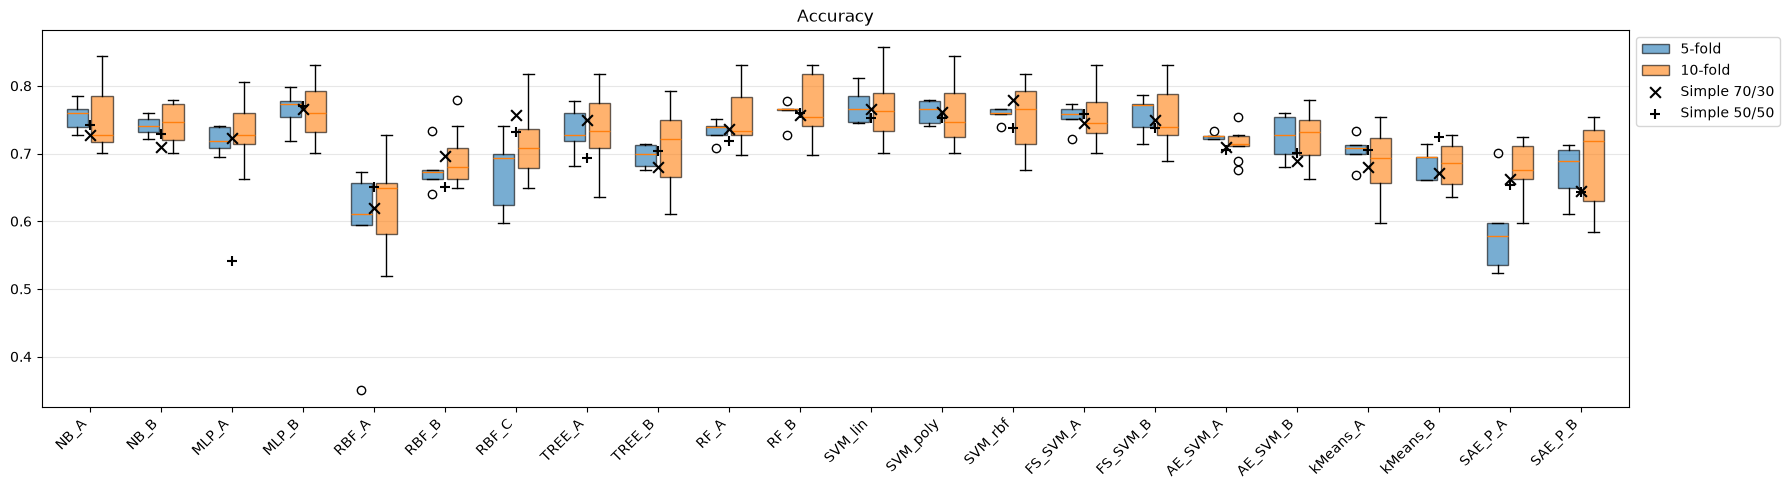

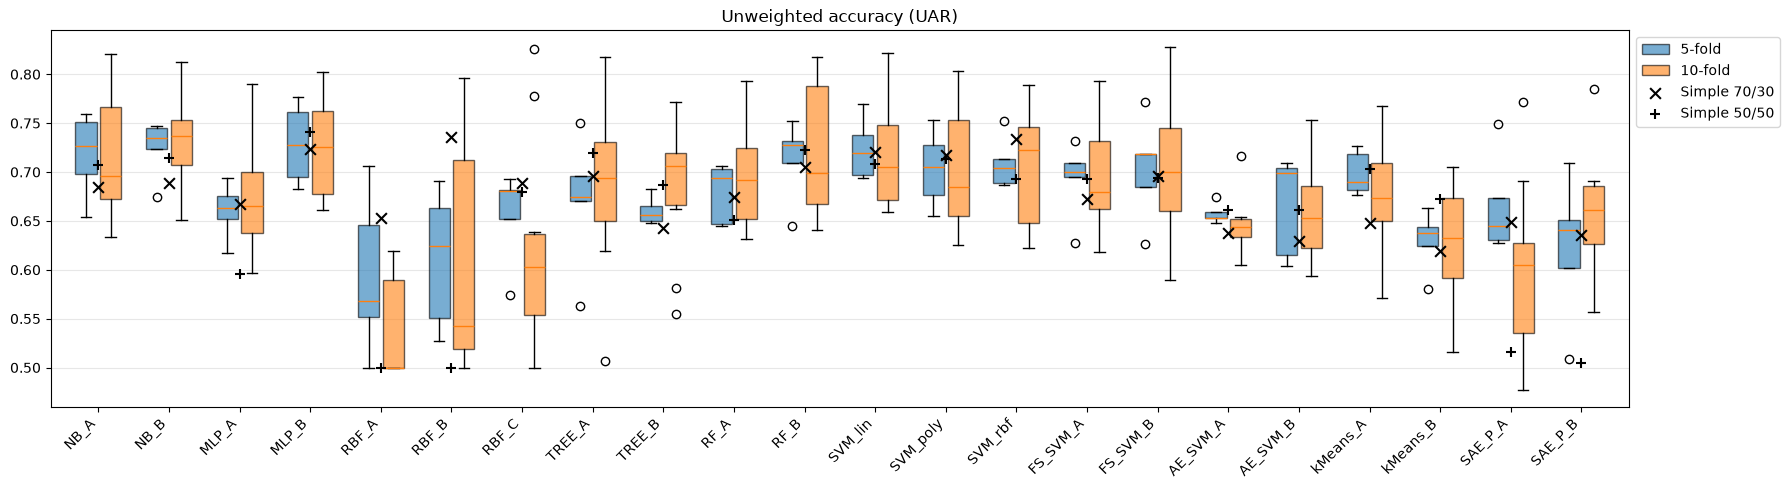

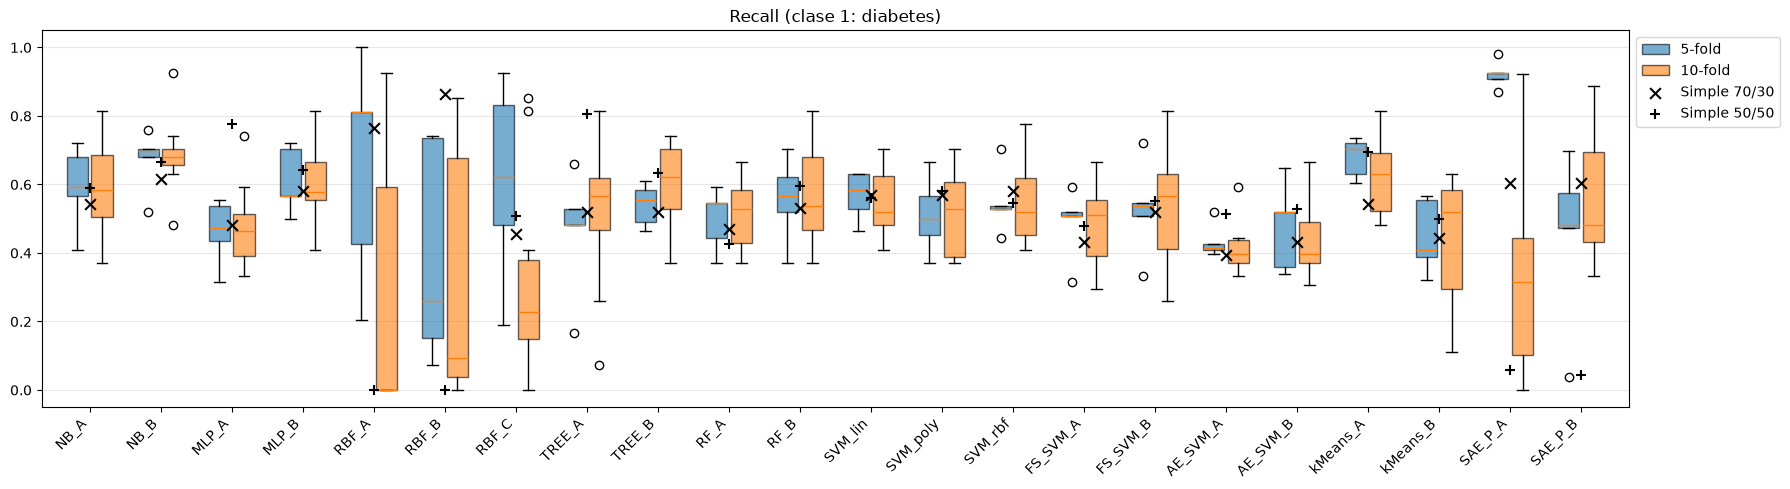

In [15]:
names = [c[0] for c in configs]
pos = np.arange(len(names))
colores = ['tab:blue', 'tab:orange']
marcadores = ['x', '+']

for metric, titulo in [('acc', 'Accuracy'), ('uar', 'Unweighted accuracy (UAR)'), ('rec', 'Recall (clase 1: diabetes)')]:
    fig, ax = plt.subplots(figsize=(18, 5))
    handles = []
    for s, kf_name in enumerate(kfold_results):
        bp = ax.boxplot(list(kfold_results[kf_name][metric]), positions=pos + (s - 0.5)*0.35,
                        widths=0.3, patch_artist=True)
        for box in bp['boxes']:
            box.set_facecolor(colores[s])
            box.set_alpha(0.6)
        handles.append(bp['boxes'][0])
    for s, split_name in enumerate(simple_results):
        handles.append(ax.scatter(pos, simple_results[split_name][metric], marker=marcadores[s], color='k', s=60, zorder=3))
    ax.legend(handles, list(kfold_results) + list(simple_results), loc='upper left', bbox_to_anchor=(1.0, 1.0))
    ax.set_xticks(pos)
    ax.set_xticklabels(names, rotation=45, ha='right')
    ax.set_title(titulo)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

**Conclusiones**

**1. Naive Bayes:** Con *priors* empíricos (NB_A) obtiene 0.755 / 0.718 y 0.751 / 0.714, un desempeño cercano al de los mejores clasificadores, pese a que la hipótesis de independencia no se cumple (por ejemplo, *Edad* y *Num_Emb* están correlacionados). Con *priors* uniformes (NB_B), la ACC baja alrededor de un punto (0.741 y 0.745), pero el recall sube de ≈ 0.59 a ≈ 0.67–0.69 y el UAR resulta el más alto de todo el estudio con 10-fold (0.731). Cambiar el *prior* equivale a mover el umbral de decisión, se gana sensibilidad a costa de especificidad.

**2. MLP:** Con 100 épocas, la red grande (MLP_B) supera a la pequeña. MLP_B alcanza 0.764 / 0.729 con ambos k (el mayor UAR en 5-fold) y un recall de ≈ 0.60–0.61. MLP_A (8-5-3-1) queda en 0.720 / 0.660 y 0.732 / 0.672, con recall ≈ 0.46–0.47, y es inestable (en la partición 50/50 su ACC cae a 0.542). Con mini-lotes de 200 muestras, 100 épocas son sólo ≈ 300–400 actualizaciones de los pesos, y la red chica no llega a ajustarse. En el primer fold de 5-fold su ACC de entrenamiento es 0.72, similar a la de test (0.74). La red grande (≈ 2700 pesos) aprende más rápido y el límite de épocas actúa como una parada temprana.

**3. RBF:** Es la familia con peor desempeño. RBF_A queda por debajo de la línea de base trivial (ACC 0.577 ± 0.117 en 5-fold). El motivo es que $\sigma_j$ se estima como el desvío *por dimensión*, mientras que en 8 dimensiones la distancia típica al centro es ≈ $\sqrt{8}\,\sigma_j$. Las gaussianas quedan demasiado angostas y sus salidas son prácticamente nulas para la mayoría de las muestras. Al ensanchar las RBF (RBF_B, σ × 4) la ACC sube a 0.677 / 0.691, y con 32 centros (RBF_C) llega a 0.715 en 10-fold. Aun así, el recall varía muchísimo entre folds, hay folds con recall 0 y otros con recall > 0.8. Esto se debe a la capa de salida. El perceptrón simple no converge cuando los datos no son linealmente separables y se detiene en una solución arbitraria, a veces casi constante. Un ajuste por mínimos cuadrados o una regresión logística en la salida sería más estable.

**4. Árbol de decisión:** El árbol poco profundo (TREE_A, 0.733 / 0.671 y 0.740 / 0.687) supera al árbol completo (TREE_B, 0.697 / 0.661 y 0.710 / 0.683), que memoriza el entrenamiento (hojas puras) y sobreajusta. TREE_A tiene un recall muy variable (desvío 0.16–0.20), con sólo 8 hojas, pequeños cambios en los datos modifican las particiones elegidas. TREE_B tiene más recall (≈ 0.54–0.60) porque genera hojas específicas para la clase minoritaria.

**5. Random forest:** El ensamble regulariza al árbol. RF_A (10 árboles completos) mejora a TREE_B: 0.733 / 0.679 y 0.751 / 0.696. RF_B (300 árboles de profundidad ≤ 6) logra 0.760 / 0.713 y 0.768 / 0.722, la mayor ACC en 10-fold. Más árboles reducen la varianza del voto, y limitar la profundidad evita que cada árbol sobreajuste.

**6. SVM:** El kernel lineal es el mejor (0.771 / 0.724 en 5-fol), seguido por el polinomial (0.762 / 0.704) y el RBF (0.758 / 0.709). Que un kernel más flexible no mejore indica que la frontera útil es aproximadamente lineal; el resto del error se debe al solapamiento de las clases que se observa en la proyección PCA de la Figura 1. Los SVM son además muy estables.

**7. Selección de características + SVM:** Con sólo 2 atributos (*Gluc_Plas* y *Masa_Corp*, los de mayor estadístico F: 213 y 72), FS_SVM_A obtiene 0.754 / 0.693, apenas por debajo del SVM_rbf con los 8 atributos. Con 4 atributos (FS_SVM_B: 0.757 / 0.704) iguala al SVM completo. La mayor parte de la información discriminante está en la glucosa y la masa corporal. Al descartar atributos baja algo el recall (0.49 frente a 0.55), pero el modelo resulta más simple e interpretable.

**8. Autocodificador + SVM:** Con 100 épocas, ambas configuraciones quedan por debajo del SVM sobre los atributos originales. AE_SVM_A (latente de 2 dimensiones) obtiene 0.725 / 0.657 y 0.715 / 0.644, y AE_SVM_B (latente de 4) 0.724 / 0.666 y 0.727 / 0.658, con recall ≈ 0.41–0.48. El autocodificador es no supervisado, conserva lo necesario para reconstruir la entrada, no para separar las clases. Además, con pocas épocas la reconstrucción queda lejos de su mínimo, por lo que pasar de 2 a 4 dimensiones latentes casi no aporta.

**9. k-means:** Con k = 2 (kMeans_A), la ACC es baja (0.704 y 0.689), pero el recall es alto (0.68 y 0.63) y el UAR es competitivo (0.699 y 0.674). Con k = 8 (kMeans_B), la ACC es similar (0.685 y 0.682), pero el recall cae a ≈ 0.45 porque la mayoría de los clústers quedan etiquetados con la clase mayoritaria. Al ser un método no supervisado, las regiones que encuentra no se alinean necesariamente con las clases.

**10. Autocodificadores apilados + perceptrón:** Con 100 épocas, ambos quedan entre los peores y son muy inestables. SAE_P_A (8-6-4) obtiene 0.587 / 0.665 en 5-fold, prediciendo casi todo como diabetes (recall 0.92), y 0.678 / 0.600 en 10-fold, con recall 0.34 ± 0.29. SAE_P_B (8-16-8) logra 0.673 / 0.622 y 0.688 / 0.657. En la partición 50/50 ambos predicen casi todo como clase 0 (recall 0.06 y 0.04). Igual que en la RBF, la inestabilidad proviene del perceptrón de salida y de la falta de *fine-tuning* supervisado de toda la pila, y se agrava porque cada autocodificador recibe pocas épocas de entrenamiento.

De forma general, no puede afirmarse que dentro de los mejores modelos, uno sea mejor que otro para este caso, muchos están dentro del desvío del otro. El techo de desempeño lo impone el solapamiento de las clases, más que el clasificador. Los modelos simples o regularizados tienden a superar a sus versiones de mayor capacidad (TREE_A > TREE_B, RF_B con profundidad limitada > RF_A, SVM lineal ≥ SVM no lineal). En el MLP pasa lo contrario, porque con 100 épocas la red chica no llega a ajustarse. Las épocas afectan sobre todo a los modelos basados en autocodificadores (AE_SVM y SAE_P), que quedan fuera del grupo líder. En todos los casos el recall de la clase "diabetes" es bajo (≈ 0.51–0.61 en el grupo líder, salvo NB_B con ≈ 0.67–0.69) por el desbalance de clases. Para un problema de diagnóstico conviene priorizar UAR y recall frente a la ACC. Con ese criterio se destacan NB_B, MLP_B y kMeans_A.

#### Curvas ROC (k-fold) para MLP y SVM


Se varía el umbral sobre la probabilidad estimada de la clase positiva para el MLP y sobre la función de decisión para el SVM. En cada fold se calcula la curva ROC sobre los datos de prueba, se interpola sobre una grilla común de FPR y se promedian las curvas.

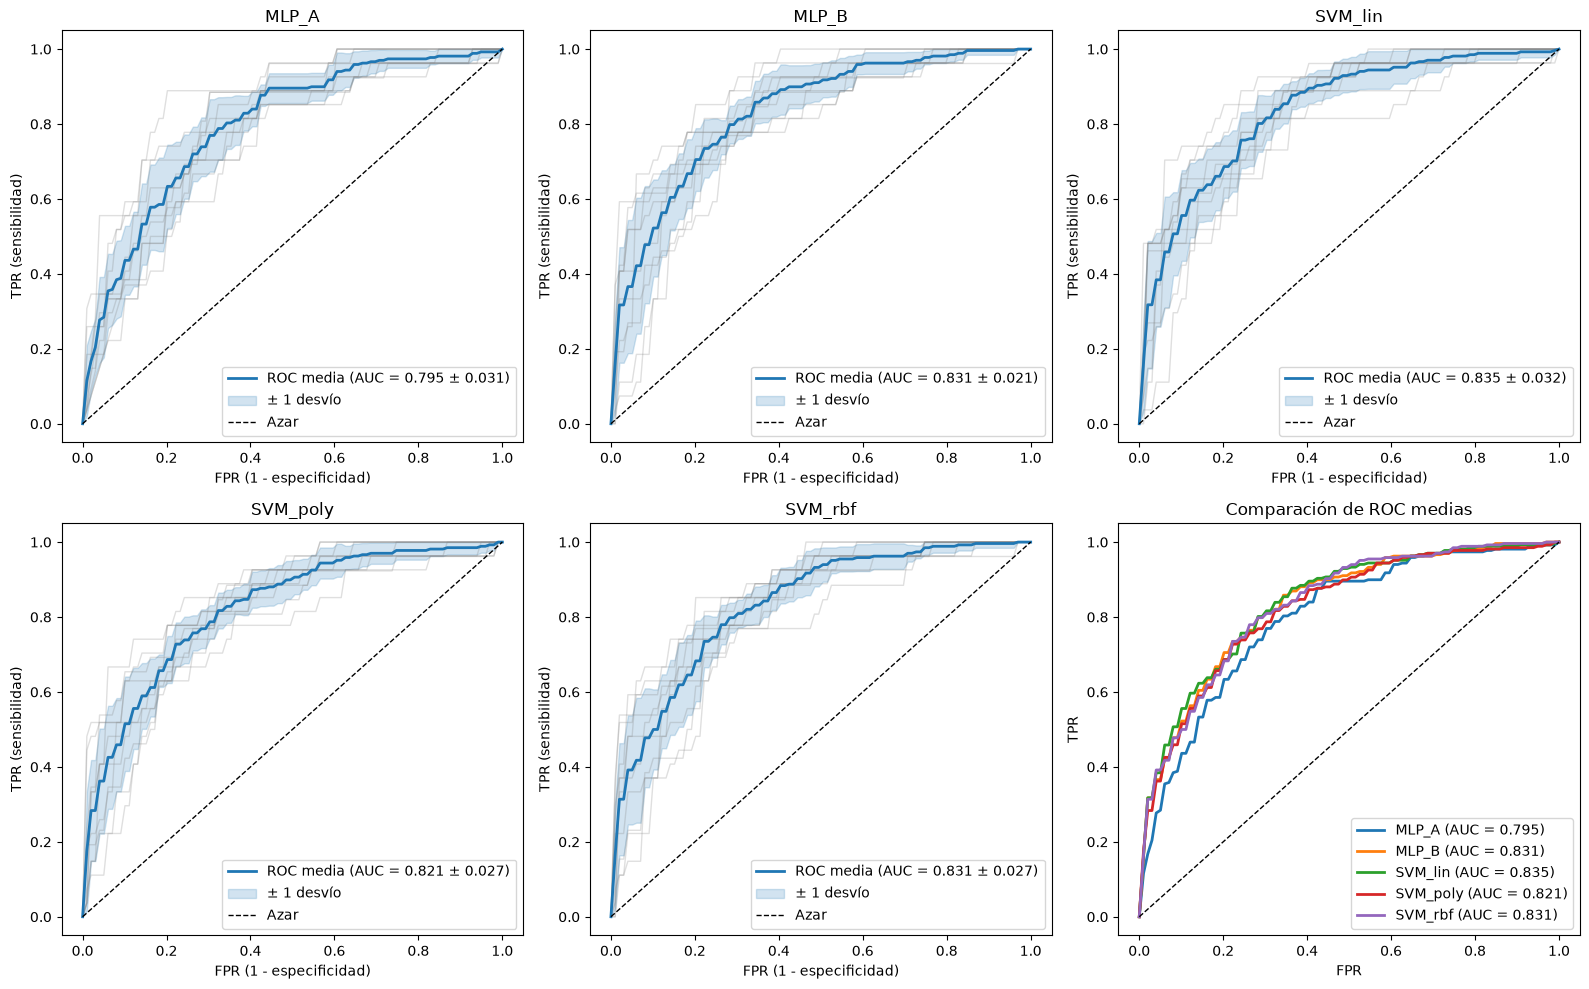

╒══════════════╤══════════╤═════════╕
│ Clasificador │ AUC Mean │ AUC STD │
├──────────────┼──────────┼─────────┤
│    MLP_A     │  0.7955  │ 0.0311  │
├──────────────┼──────────┼─────────┤
│    MLP_B     │  0.8309  │ 0.0214  │
├──────────────┼──────────┼─────────┤
│   SVM_lin    │  0.8350  │ 0.0323  │
├──────────────┼──────────┼─────────┤
│   SVM_poly   │  0.8206  │ 0.0270  │
├──────────────┼──────────┼─────────┤
│   SVM_rbf    │  0.8305  │ 0.0271  │
╘══════════════╧══════════╧═════════╛


In [16]:
from sklearn.metrics import roc_curve, auc

kf = StratifiedKFold(n_splits=10)
roc_configs = [c for c in configs if c[1] in (clf_MLP, clf_SVM)]
mean_fpr = np.linspace(0, 1, 100)
roc_results = {}

for name, func, params in roc_configs:
    tprs, aucs = [], []
    for train_index, test_index in kf.split(X, Y):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = Y[train_index], Y[test_index]
        scaler = StandardScaler().fit(X_train)
        X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
        *_, model = func(X_train, X_test, y_train, y_test, return_model=True, **params)
        if func is clf_MLP:
            score = model.predict_proba(X_test)[:, 1]   # probabilidad estimada de la clase 1
        else:
            score = model.decision_function(X_test)     # distancia (con signo) al hiperplano
        fpr, tpr, _ = roc_curve(y_test, score)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(auc(fpr, tpr))
    roc_results[name] = dict(tprs=np.array(tprs), aucs=np.array(aucs))

# gráficos: una curva promedio por configuración (+/- 1 desvío) y comparación final
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
for i, name in enumerate(roc_results):
    tprs, aucs = roc_results[name]['tprs'], roc_results[name]['aucs']
    mean_tpr = tprs.mean(axis=0); mean_tpr[-1] = 1.0
    std_tpr = tprs.std(axis=0)
    ax = axes[i]
    for t in tprs:
        ax.plot(mean_fpr, t, color='gray', alpha=0.25, lw=1)
    ax.plot(mean_fpr, mean_tpr, color='tab:blue', lw=2,
            label='ROC media (AUC = %.3f $\\pm$ %.3f)' % (aucs.mean(), aucs.std()))
    ax.fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0), np.minimum(mean_tpr + std_tpr, 1),
                    color='tab:blue', alpha=0.2, label='$\\pm$ 1 desvío')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
    ax.set_title(name); ax.set_xlabel('FPR (1 - especificidad)'); ax.set_ylabel('TPR (sensibilidad)')
    ax.legend(loc='lower right')
ax = axes[len(roc_results)]
for name in roc_results:
    mean_tpr = roc_results[name]['tprs'].mean(axis=0); mean_tpr[-1] = 1.0
    ax.plot(mean_fpr, mean_tpr, lw=2, label='%s (AUC = %.3f)' % (name, roc_results[name]['aucs'].mean()))
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_title('Comparación de ROC medias'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.legend(loc='lower right')
for ax in axes[len(roc_results)+1:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

table = [["Clasificador", "AUC Mean", "AUC STD"]]
for name in roc_results:
    table.append([name, '%.4f' % roc_results[name]['aucs'].mean(), '%.4f' % roc_results[name]['aucs'].std()])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))

* MLP_B y los tres SVM tienen AUC muy similares (0.821–0.835). La diferencia entre el mejor SVM (SVM_lin, 0.835) y MLP_B (0.831) es mucho menor que el desvío entre folds, y sus curvas medias prácticamente se superponen. MLP_B además tiene la menor dispersión (± 0.021). MLP_A queda por debajo (0.796 ± 0.031), sobre todo para FPR < 0.4, lo que es consistente con el subajuste de la red chica con 100 épocas.  

* La comparación entre la probabilidad estimada del MLP y la función de decisión del SVM es válida, porque la curva ROC y el AUC sólo dependen del *orden* de los puntajes. Son invariantes a transformaciones monótonas, así que las escalas distintas no influyen.  

* Un AUC ≈ 0.83 junto con un UAR ≈ 0.72–0.73 indica que el umbral por defecto (probabilidad 0.5 o función de decisión 0) no es el mejor punto de operación. Con ese umbral, el recall es ≈ 0.55–0.61 con FPR ≈ 0.12–0.15. Según la curva media, aceptando FPR ≈ 0.3 la sensibilidad sube a ≈ 0.8, un compromiso más razonable para un contexto médico, donde un falso negativo es más costoso.

#### Comparación de los métodos de validación

* **Particionado simple:** Produce una única estimación, cuyo valor depende de la partición elegida, y no permite conocer su variabilidad. Por ejemplo, TREE_A obtiene ACC 0.749 (70/30) frente a 0.693 (50/50) y recall 0.52 frente a 0.81; MLP_A pasa de ACC 0.723 a 0.542, SAE_P_A de recall 0.60 a 0.06, y RBF_B de 0.86 a 0.00. El orden de los clasificadores también cambia. Con 70/30 el mejor es SVM_rbf (0.779), mientras que con 50/50 es MLP_B (0.771), seguido de RF_B (0.760) y FS_SVM_A (0.758). La partición 50/50 entrena con menos datos (384 muestras), pero evalúa sobre más, por lo que su estimación es menos ruidosa, aunque algo pesimista. En los boxplots, los puntos de las particiones simples caen en general dentro del rango de los folds. Una partición simple es sólo una muestra de esa distribución.  

* **5-fold frente a 10-fold:** Las medias son muy parecidas, por ejemplo, NB_A 0.755 / 0.751, MLP_B 0.764 / 0.764, SVM_lin 0.771 / 0.767 y RF_B 0.760 / 0.768. En 10-fold algunos modelos mejoran levemente (RF_A, RBF_C, MLP_A) porque cada fold entrena con el 90 % de los datos en lugar del 80 %, lo que reduce el sesgo pesimista. El desvío entre folds es mayor con 10-fold (≈ 0.03–0.05 en ACC frente a ≈ 0.01–0.03), porque cada fold de test tiene sólo ≈ 77 muestras. Mayor desvío por fold no significa que la estimación de la media sea peor, 10-fold promedia el doble de valores.  

* **Métricas:** El recall tiene cajas mucho más anchas que la ACC y el UAR, porque se calcula sólo sobre los positivos de cada fold (≈ 54 con k = 5 y ≈ 27 con k = 10). El UAR tiene una dispersión intermedia.  

---

---

### **Ejercicio 2: dataset "Iris"**

In [12]:
# carga de datos
iris = load_iris()
# aleatorización
X, Y = shuffle(iris.data, iris.target, random_state=0)
print('Patrones: %d | Atributos: %d | Patrones por clase:' % X.shape, np.bincount(Y))

# defino la lista de configuraciones a evaluar: (nombre, función del clasificador, parámetros)
# (los autocodificadores usan un espacio latente de 2 dimensiones)
configs = [
    # 1 Naive Bayes
    ("NB_A",     clf_NB,     dict(var_smoothing=1e-9)),
    ("NB_B",     clf_NB,     dict(var_smoothing=0.5)),
    # 2 Perceptrón multicapa
    ("MLP_A",    clf_MLP,    dict(hidden_layer_sizes=(5,3),   activation='relu', learning_rate_init=0.001, max_iter=1000)),
    ("MLP_B",    clf_MLP,    dict(hidden_layer_sizes=(64,32), activation='relu', learning_rate_init=0.001, max_iter=1000)),
    # 3 Red RBF
    ("RBF_A",    clf_RBF,    dict(n_clusters=3, sigma_scale=1.0)),
    ("RBF_B",    clf_RBF,    dict(n_clusters=9, sigma_scale=2.0)),
    # 4 Árbol de decisión
    ("TREE_A",   clf_TREE,   dict(max_depth=2)),
    ("TREE_B",   clf_TREE,   dict(max_depth=None)),
    # 5 Random forest
    ("RF_A",     clf_RF,     dict(n_estimators=10,  max_depth=None)),
    ("RF_B",     clf_RF,     dict(n_estimators=300, max_depth=3)),
    # 6 SVM
    ("SVM_lin",  clf_SVM,    dict(kernel='linear', C=1.0)),
    ("SVM_poly", clf_SVM,    dict(kernel='poly', degree=2, coef0=1, gamma='auto', C=1.0)),
    ("SVM_rbf",  clf_SVM,    dict(kernel='rbf', gamma='scale', C=1.0)),
    # 7 Selección de características (ANOVA F) + SVM
    ("FS_SVM_A", clf_FS_SVM, dict(k=1, kernel='rbf', gamma='scale')),
    ("FS_SVM_B", clf_FS_SVM, dict(k=2, kernel='rbf', gamma='scale')),
    # 8 Autocodificador + SVM (espacio latente de 2 dimensiones)
    ("AE_SVM_A", clf_AE_SVM, dict(n_encoder1=8,  n_encoder2=4,  n_latent=2, learning_rate_init=0.001, max_iter=1000, kernel='rbf', gamma='scale')),
    ("AE_SVM_B", clf_AE_SVM, dict(n_encoder1=32, n_encoder2=16, n_latent=2, learning_rate_init=0.001, max_iter=1000, kernel='rbf', gamma='scale')),
    # 9 k-means
    ("kMeans_A", clf_kMeans, dict(n_clusters=3)),
    ("kMeans_B", clf_kMeans, dict(n_clusters=9)),
    # 10 Autocodificadores apilados + perceptrón (última capa de 2 dimensiones)
    ("SAE_P_A",  clf_SAE_P,  dict(layers=(3,2), max_iter=1000)),
    ("SAE_P_B",  clf_SAE_P,  dict(layers=(8,2), max_iter=1000)),
]

Patrones: 150 | Atributos: 4 | Patrones por clase: [50 50 50]


#### Modelos

Tenemos 150 muestras con 4 atributos (largo y ancho de sépalo y de pétalo), 50 de cada clase (0 = *setosa*, 1 = *versicolor*, 2 = *virginica*). Al estar las clases balanceadas, ACC y UAR resultan muy parecidas. Igual que en el ejercicio anterior, se estandarizan los atributos ajustando el `StandardScaler` sólo con los datos de entrenamiento.

Se estudian dos configuraciones de cada uno de los 10 modelos (tres en el caso del SVM). Los autocodificadores usan un espacio latente de 2 dimensiones y todos los modelos entrenados por épocas usan un máximo de 1000. A diferencia del Ejercicio 1, con sólo 135 muestras de entrenamiento cada mini-lote de 200 abarca todo el conjunto, por lo que cada época es una única actualización de los pesos y 100 épocas no alcanzan para entrenar las redes. A continuación, se detallan las características principales de cada modelo/configuración:

1. **Naive Bayes**: cada atributo se modela con una normal univariada por clase. Las probabilidades a priori se estiman de train (≈ 1/3 por clase).  
    a) **NB_A**: `var_smoothing` $=10^{-9}$ (valor por defecto).  
    b) **NB_B**: `var_smoothing` $=0.5$. A todas las varianzas se les suma la mitad de la varianza máxima (≈ 0.5 con datos estandarizados), lo que ensancha mucho las gaussianas.

2. **Perceptrón multicapa**:  
    a) **MLP_A**: Estructura de 4-5-3-3 (ReLU, salida *softmax*). Optimizador Adam con tasa de aprendizaje $0.001$, regularización $L_2=1e-4$, 1000 épocas máximas.  
    b) **MLP_B**: Estructura de 4-64-32-3. El resto de los parámetros se mantienen igual que el caso anterior.

3. **RBF**:  
    a) **RBF_A**: Capa oculta de 3 gaussianas con centros obtenidos por *k-means* sobre train y el ancho original (desvío medio de las muestras del clúster). La capa de salida es un perceptrón simple.  
    b) **RBF_B**: 9 centros con anchos 2 veces mayores (`sigma_scale = 2`).

4. **Árbol de decisión**:  
    a) **TREE_A**: Criterio Gini, profundidad máxima 2.  
    b) **TREE_B**: Criterio Gini, sin límite de profundidad.

5. **Random Forest**:  
    a) **RF_A**: 10 árboles sin límite de profundidad, *bootstrap*, $\sqrt{4}=2$ atributos candidatos por partición.  
    b) **RF_B**: 300 árboles con profundidad máxima 3.

6. **SVM** (multiclase, uno contra uno):  
    a) **SVM_lin**: Kernel lineal, $C=1$.  
    b) **SVM_poly**: Kernel polinomial de grado 2, $\gamma = 1/4$ (`'auto'`), `coef0` = 1, C = 1.  
    c) **SVM_rbf**: Kernel gaussiano, $\gamma$ = `'scale'`, C = 1.

7. **Selección de características y SVM**:  
    a) **FS_SVM_A**: Ranking ANOVA F con $k=1$ seguido de un SVM RBF ($\gamma=$`'scale'`, $C=1$). En todos los folds se elige *petal length*.  
    b) **FS_SVM_B**: Igual que el anterior con $k=2$, se agrega *petal width*.

8. **Autocodificador MLP y SVM**:  
    a) **AE_SVM_A**: Autocodificador MLP 4–8–4–**2**–4–8–4 (tanh, Adam con $lr=0.001$, 1000 épocas). Sobre el espacio latente de 2 dimensiones se entrena un SVM RBF ($\gamma=$`'scale'`, $C=1$).  
    b) **AE_SVM_B**: Autocodificador MLP 4–32–16–**2**–16–32–4. Igual que el anterior.

9. **K-means**:  
    a) **kMeans_A**: $k=3$ sobre train (un clúster por clase). Cada clúster recibe la clase mayoritaria de sus muestras de train y cada patrón de test toma la etiqueta del centroide más cercano.  
    b) **kMeans_B**: $k=9$ y mismo etiquetado.

10. **Autocodificador apilado y perceptrón**:  
    a) **SAE_P_A**: Autocodificadores apilados entrenados capa por capa (AE1 4-3-4, AE2 3-2-3), tanh, Adam con lr = 0.001, 1000 épocas cada uno. Sobre la representación de 2 dimensiones se entrena un perceptrón simple.  
    b) **SAE_P_B**: Igual al anterior pero con AE1 4-8-4 y AE2 8-2-8.

#### Validación

* **k-fold no estratificado** (k = 10): es el método con el que se comparan los clasificadores. Cada fold de test tiene 15 muestras, por lo que un error equivale a 0.067 de ACC. Se reportan la media y el desvío estándar sobre los folds.
* El particionado simple 70/30 se mantiene sólo como referencia.

**Validación cruzada: particionado simple train/test**

In [13]:
# validación cruzada: partición train/test
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=0, shuffle=True, stratify=Y)

# Estandarización de los datos
scaler = StandardScaler()
# Ajuste sobre de train
scaler.fit(X_train)
# transformación de datos train y test
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
vacc = []
vuar = []
vnf  = []
# llamada a cada clasificador
for clf in range(0,len(configs)):
    name, func, params = configs[clf]
    acc, uar, _, nf = func(X_train, X_test, y_train, y_test, **params)
    # guardo las medidas de desempeño en un vector
    vacc.append(acc)
    vuar.append(uar)
    vnf.append(nf)

# imprimo una tabla con los resultados
print(':::                  Simple CV                  :::')
table = [["Clasificador","ACC", "UAR", "# Features"]]
for clf in range(0,len(configs)):
    table.append([ configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], '%1.1f' % vnf[clf] ])
print(tabulate(table, tablefmt="fancy_grid", showindex="always",stralign="center"))

:::                  Simple CV                  :::
╒════╤══════════════╤════════╤════════╤════════════╕
│  0 │ Clasificador │  ACC   │  UAR   │ # Features │
├────┼──────────────┼────────┼────────┼────────────┤
│  1 │     NB_A     │ 0.9556 │ 0.9556 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  2 │     NB_B     │ 0.8889 │ 0.8889 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  3 │    MLP_A     │ 0.9556 │ 0.9556 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  4 │    MLP_B     │ 0.9333 │ 0.9333 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  5 │    RBF_A     │ 0.7111 │ 0.7111 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  6 │    RBF_B     │ 0.8000 │ 0.8000 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  7 │    TREE_A    │ 0.9556 │ 0.9556 │    4.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  8 │    TREE_B    │ 0.9556 │ 0.9556 │    4.0 

**K-Fold Cross Validation**

/home/eclaucich/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/eclaucich/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/home/eclaucich/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/eclaucich/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


:::                            10-fold CV                               :::
╒════╤══════════════╤══════════╤═════════╤══════════╤═════════╤════════════╕
│  0 │ Clasificador │ ACC Mean │ ACC STD │ UAR Mean │ UAR STD │ # Features │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  1 │     NB_A     │  0.9533  │ 0.0600  │  0.9597  │ 0.0479  │    4.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  2 │     NB_B     │  0.8867  │ 0.1077  │  0.8732  │ 0.1191  │    4.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  3 │    MLP_A     │  0.9467  │ 0.0581  │  0.9467  │ 0.0503  │    4.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  4 │    MLP_B     │  0.9600  │ 0.0611  │  0.9661  │ 0.0479  │    4.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  5 │    RBF_A     │  0.6933  │ 0.1236  │  0.6470  │ 0.1419  │    4.0     │


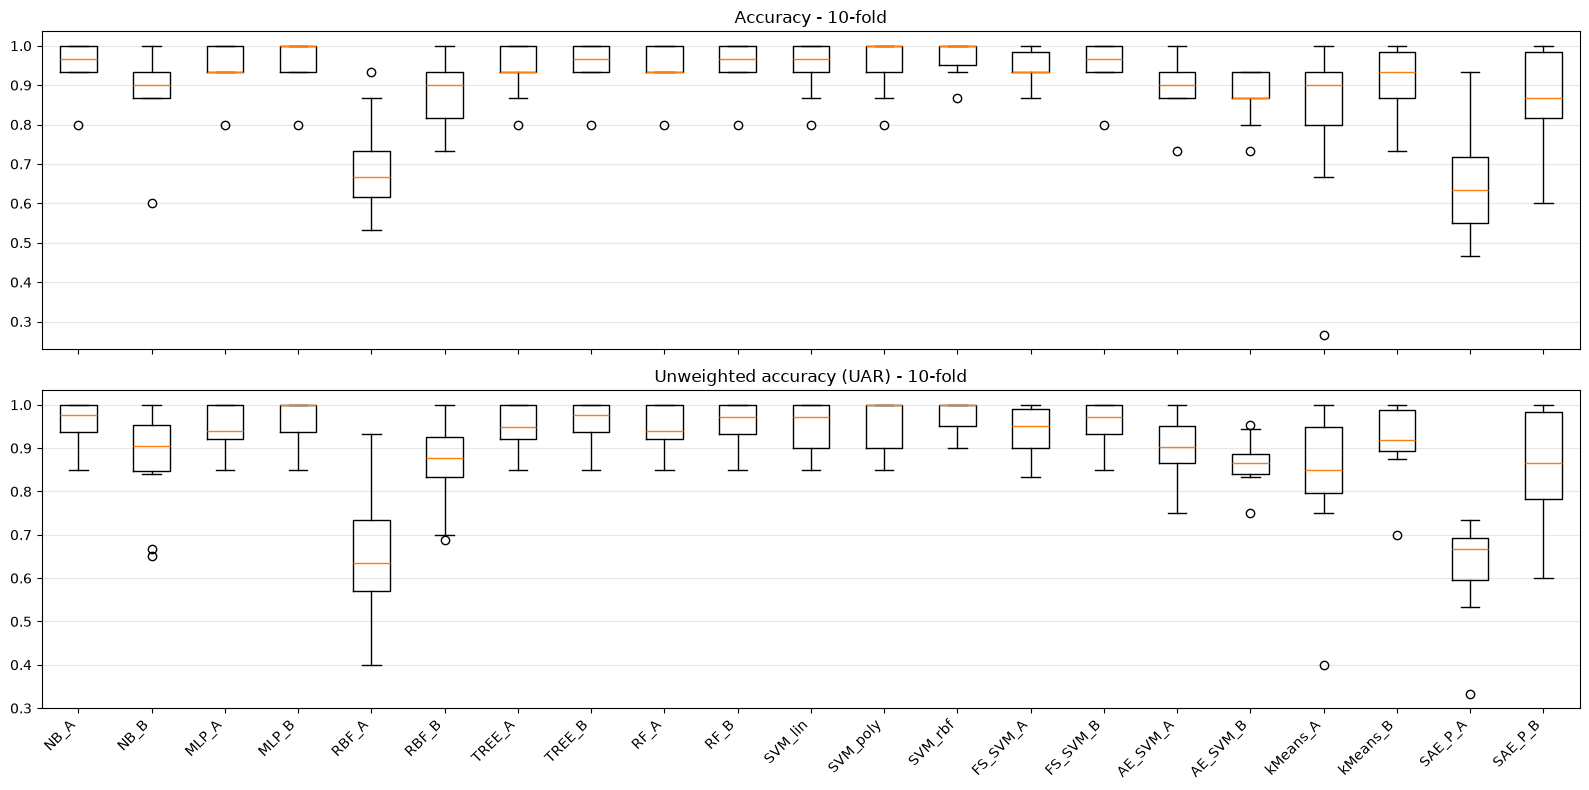

In [14]:
NFfolds = 10   # >=2

# inicializo estructuras para guardar resultados
Macc = [[] for i in range(len(configs))]
Muar = [[] for i in range(len(configs))]
Mnf  = [[] for i in range(len(configs))]

# Validación cruzada K-Fold (estratificada / no estratificada)

kf = KFold(n_splits=NFfolds)                            # non Stratified KFold
# kf = StratifiedKFold(n_splits=NFfolds)                # Stratified KFold

for train_index, test_index in kf.split(X):

    # asigno datos y etiquetas segun los índices del fold
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = Y[train_index], Y[test_index]

    # Estandarización de los datos (sobre cada fold)
    scaler = StandardScaler()
    # Ajuste sobre de train
    scaler.fit(X_train)
    # transformación de datos train y test
    X_train = scaler.transform(X_train)
    X_test = scaler.transform(X_test)

    # llamada a cada clasificador con el fold actual
    for clf in range(0,len(configs)):
        name, func, params = configs[clf]
        acc, uar, _, nf = func(X_train, X_test, y_train, y_test, **params)
        # guardo las medidas de desempeño en un vector
        Macc[clf].append(acc)
        Muar[clf].append(uar)
        Mnf[clf].append(nf)

# conversión a array
Macc = np.array(Macc)
Muar = np.array(Muar)
Mnf  = np.array(Mnf)
# guardo los resultados por fold (se usan en el test de significancia y en la validación del mejor clasificador)
iris_kfold = dict(acc=Macc, uar=Muar)
# estadísticas de desempeño
acc_mean = np.mean(Macc,axis=1)
uar_mean = np.mean(Muar,axis=1)
nf_mean  = np.mean(Mnf,axis=1)
acc_std = np.std(Macc,axis=1)
uar_std = np.std(Muar,axis=1)

# imprimo una tabla con los resultados
print(':::                            %d-fold CV                               :::' % NFfolds)
table = [["Clasificador","ACC Mean","ACC STD","UAR Mean","UAR STD", "# Features"]]
for clf in range(0,len(configs)):
    table.append([configs[clf][0], '%.4f' % acc_mean[clf], '%.4f' % acc_std[clf], '%.4f' % uar_mean[clf], '%.4f' % uar_std[clf], '%1.1f' % nf_mean[clf]])
print(tabulate(table, tablefmt="fancy_grid", showindex="always",stralign="center"))

# BoxPlots de ACC y UAR sobre los folds
names = [c[0] for c in configs]
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, metric, titulo in [(axes[0], 'acc', 'Accuracy'), (axes[1], 'uar', 'Unweighted accuracy (UAR)')]:
    ax.boxplot(list(iris_kfold[metric]))
    ax.set_title(titulo + ' - %d-fold' % NFfolds)
    ax.grid(axis='y', alpha=0.3)
axes[1].set_xticks(np.arange(1, len(names)+1))
axes[1].set_xticklabels(names, rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Conclusiones**

Los valores corresponden a ACC / UAR medios del 10-fold.

**1. Naive Bayes:** Con el suavizado por defecto (NB_A, 0.953 / 0.960) está entre los mejores. Con `var_smoothing = 0.5` (NB_B, 0.887 / 0.873) las gaussianas quedan demasiado anchas y aumenta la confusión entre *versicolor* y *virginica*.

**2. MLP:** Ambas redes están entre los mejores. La red grande (MLP_B, 0.960 / 0.966) es la segunda mejor de todo el estudio y la chica (MLP_A, 0.947 / 0.947) queda apenas por debajo. Iris es un problema casi separable y con poco ruido, por lo que la mayor capacidad de MLP_B no produce sobreajuste. La diferencia entre ambas es de 2 errores sobre 150 muestras.

**3. RBF:** RBF_A queda muy por debajo del resto (0.693 ± 0.124). Igual que en el Ejercicio 1, las gaussianas son angostas (en 4 dimensiones la distancia típica al centro es ≈ $2\sigma_j$) y el perceptrón de salida es inestable. Con 9 centros y el doble de ancho (RBF_B, 0.880 / 0.865) mejora mucho, aunque sigue por debajo de los mejores.

**4. Árbol de decisión:** Un árbol de profundidad 2 (TREE_A, 0.940 / 0.946) ya separa las clases usando las medidas del pétalo. El árbol completo (TREE_B, 0.953 / 0.961) no sobreajusta como en el Ejercicio 1, porque Iris tiene poco ruido y las clases son casi separables.

**5. Random forest:** RF_A (0.947 / 0.947) y RF_B (0.953 / 0.958) obtienen lo mismo que un árbol. En un problema tan simple el ensamble no tiene varianza que reducir.

**6. SVM:** El kernel gaussiano (SVM_rbf, 0.973 / 0.977) es el mejor de todo el estudio, seguido por el polinomial (0.953 / 0.954) y el lineal (0.947 / 0.948). A diferencia del Ejercicio 1, un kernel no lineal ajusta mejor la frontera curva entre *versicolor* y *virginica*.

**7. Selección de características + SVM:** Con un solo atributo (*petal length*), FS_SVM_A obtiene 0.947 / 0.938, y con los dos del pétalo FS_SVM_B obtiene 0.953 / 0.958, igual que el SVM polinomial con los 4 atributos. Casi toda la información discriminante está en el pétalo (estadístico F de 1180 y 960, frente a 119 y 49 de las medidas del sépalo).

**8. Autocodificador + SVM:** El autocodificador chico (AE_SVM_A, 0.893 / 0.898) supera levemente al grande (AE_SVM_B, 0.873 / 0.866). Ambos reconstruyen bien la entrada (en el último fold, la pérdida es 0.025 y 0.019), y la diferencia entre ellos (3 errores) está dentro del desvío entre folds. Los dos quedan por debajo del SVM sobre los atributos originales, ya que la compresión a 2 dimensiones es no supervisada. Conserva la separación de *setosa*, pero aumenta el solapamiento entre *versicolor* y *virginica*.

**9. k-means:** Con k = 3 (kMeans_A) la ACC es 0.813, con un desvío enorme (0.204). En algunos folds los clústers no se alinean con las clases. Con k = 9 (kMeans_B, 0.907 / 0.916) cada clase queda cubierta por varios clústers y el etiquetado por mayoría es más estable.

**10. Autocodificadores apilados + perceptrón:** SAE_P_B (4-8-2) obtiene 0.867 / 0.862, mientras que SAE_P_A (4-3-2) es el peor de todo el estudio (0.647 / 0.625). Ambos tienen desvíos altos (≈ 0.12–0.13). Al pasar primero por una capa de 8 neuronas, SAE_P_B conserva más información antes de comprimir a 2 dimensiones. Como en el Ejercicio 1, la inestabilidad proviene del perceptrón de salida y de la falta de *fine-tuning* supervisado.

De forma general, los mejores modelos (SVM_rbf 0.973; MLP_B 0.960; NB_A, TREE_B, RF_B, SVM_poly y FS_SVM_B 0.953; MLP_A, RF_A, SVM_lin y FS_SVM_A 0.947; TREE_A 0.940) están separados por a lo sumo 5 errores sobre 150 muestras. Los errores se concentran en unos pocos puntos de la frontera *versicolor*/*virginica*, mientras que *setosa* es linealmente separable. El UAR difiere levemente de la ACC porque los folds no estratificados tienen composiciones desbalanceadas.

#### Significancia estadística

Se compara de a pares la mejor configuración de cada uno de los 10 modelos (la de mayor ACC media en el 10-fold). Para cada par se aplica un *t-test* pareado sobre las accuracy de los 10 folds, con la corrección de Nadeau y Bengio. Esta corrección tiene en cuenta que los conjuntos de entrenamiento de los folds se solapan, reemplazando el factor $1/k$ por $1/k + n_{test}/n_{train}$.

Pares con diferencia significativa (p < 0.05):
  NB_A      (0.953)  vs  AE_SVM_A  (0.893):  p = 0.0263
  MLP_B     (0.960)  vs  AE_SVM_A  (0.893):  p = 0.0098
  RF_B      (0.953)  vs  AE_SVM_A  (0.893):  p = 0.0073
  SVM_rbf   (0.973)  vs  AE_SVM_A  (0.893):  p = 0.0026
  FS_SVM_B  (0.953)  vs  AE_SVM_A  (0.893):  p = 0.0073


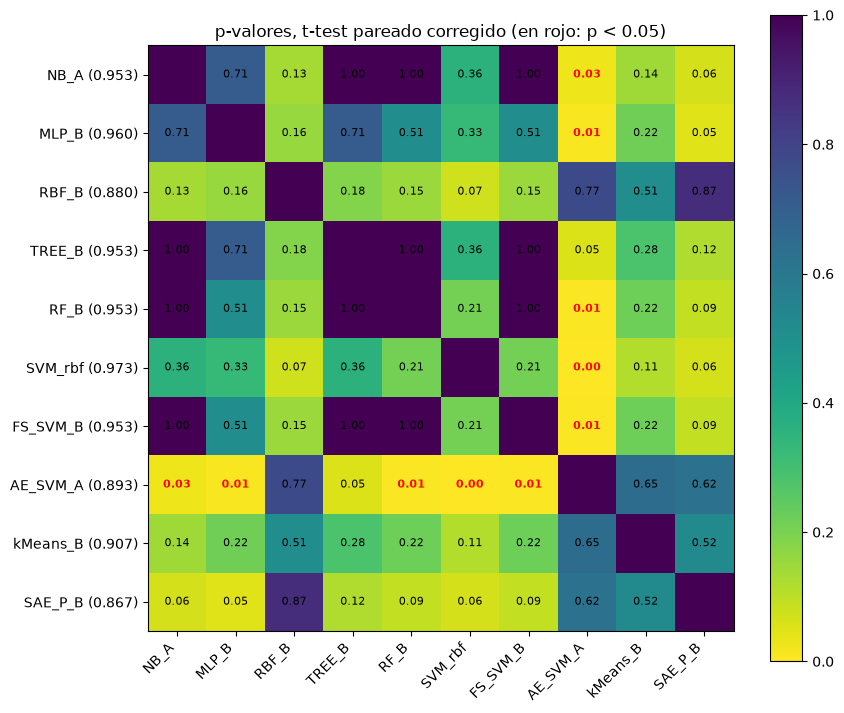

In [15]:
# t-test pareado corregido (Nadeau & Bengio, 2003) sobre las accuracy de los folds
def corrected_ttest(a, b, n_train, n_test):
    d = a - b
    k = len(d)
    var = np.var(d, ddof=1)
    if var == 0:                       # diferencias idénticas en todos los folds
        return 1.0 if np.mean(d) == 0 else 0.0
    t = np.mean(d) / np.sqrt((1.0/k + n_test/n_train) * var)
    return 2 * stats.t.sf(np.abs(t), k - 1)

# mejor configuración de cada clasificador (mayor ACC media; a igual media, menor desvío)
acc_kf = iris_kfold['acc']
fam_best = {}
for idx, (name, func, params) in enumerate(configs):
    fam = name.rsplit('_', 1)[0]
    if fam not in fam_best or (acc_kf[idx].mean(), -acc_kf[idx].std()) > (acc_kf[fam_best[fam]].mean(), -acc_kf[fam_best[fam]].std()):
        fam_best[fam] = idx
best_idx = list(fam_best.values())
best_names = [configs[idx][0] for idx in best_idx]
n_test = len(Y) / NFfolds
n_train = len(Y) - n_test

# p-valores para cada par de clasificadores
nbest = len(best_idx)
P = np.ones((nbest, nbest))
for i in range(nbest):
    for j in range(i+1, nbest):
        P[i, j] = P[j, i] = corrected_ttest(acc_kf[best_idx[i]], acc_kf[best_idx[j]], n_train, n_test)

print('Pares con diferencia significativa (p < 0.05):')
for i in range(nbest):
    for j in range(i+1, nbest):
        if P[i, j] < 0.05:
            print('  %-9s (%.3f)  vs  %-9s (%.3f):  p = %.4f' % (best_names[i], acc_kf[best_idx[i]].mean(),
                                                               best_names[j], acc_kf[best_idx[j]].mean(), P[i, j]))

# mapa de p-valores
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(P, cmap='viridis_r', vmin=0, vmax=1)
for i in range(nbest):
    for j in range(nbest):
        if i != j:
            ax.text(j, i, '%.2f' % P[i, j], ha='center', va='center', fontsize=8,
                    color='red' if P[i, j] < 0.05 else 'black', fontweight='bold' if P[i, j] < 0.05 else None)
ax.set_xticks(range(nbest)); ax.set_xticklabels(best_names, rotation=45, ha='right')
ax.set_yticks(range(nbest)); ax.set_yticklabels(['%s (%.3f)' % (n, acc_kf[idx].mean()) for n, idx in zip(best_names, best_idx)])
ax.set_title('p-valores, t-test pareado corregido (en rojo: p < 0.05)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

* Sólo 5 de los 45 pares tienen una diferencia significativa (p < 0.05), y todos involucran a AE_SVM_A (0.893). NB_A, MLP_B, RF_B, SVM_rbf y FS_SVM_B lo superan significativamente. TREE_B, con la misma media que NB_A o RF_B, queda justo en el límite (p ≈ 0.05).

* Las configuraciones con medias más bajas que AE_SVM_A no se diferencian significativamente del grupo líder, por ejemplo SAE_P_B (0.867, p entre 0.05 y 0.12) o RBF_B (0.880, p entre 0.07 y 0.18). Sus resultados varían mucho entre folds (desvío ≈ 0.09–0.12), y el test corregido tiene en cuenta esa variabilidad.

* La mejora del mejor clasificador (SVM_rbf, 0.973) sólo es significativa frente a AE_SVM_A. Frente a MLP_B (0.960) el p-valor es 0.33, y frente al resto del grupo líder (0.953) está entre 0.21 y 0.36. Varios pares tienen exactamente las mismas accuracy en todos los folds (p = 1).

* Con 10 folds de 15 muestras el test tiene poca potencia, y al hacer 45 comparaciones alguna diferencia puede resultar significativa por azar.

#### Validación del mejor clasificador

Se toma la configuración con mayor ACC media en el 10-fold (SVM_rbf) y se repite la validación con k-fold estratificado (k = 10) y con particionado simple 70/30 estratificado repetido k = 10 veces. Se comparan la media y la varianza de la ACC sobre las 10 particiones de cada método.

Mejor configuración: SVM_rbf {'kernel': 'rbf', 'gamma': 'scale', 'C': 1.0}
╒══════════════════════════════╤══════════╤═════════╤═════════╕
│           Esquema            │ ACC Mean │ ACC STD │ ACC Var │
├──────────────────────────────┼──────────┼─────────┼─────────┤
│   KFold (no estratificado)   │  0.9733  │ 0.0442  │ 0.00196 │
├──────────────────────────────┼──────────┼─────────┼─────────┤
│       StratifiedKFold        │  0.9733  │ 0.0442  │ 0.00196 │
├──────────────────────────────┼──────────┼─────────┼─────────┤
│ Partición simple x10 (70/30) │  0.9533  │ 0.0252  │ 0.00064 │
╘══════════════════════════════╧══════════╧═════════╧═════════╛


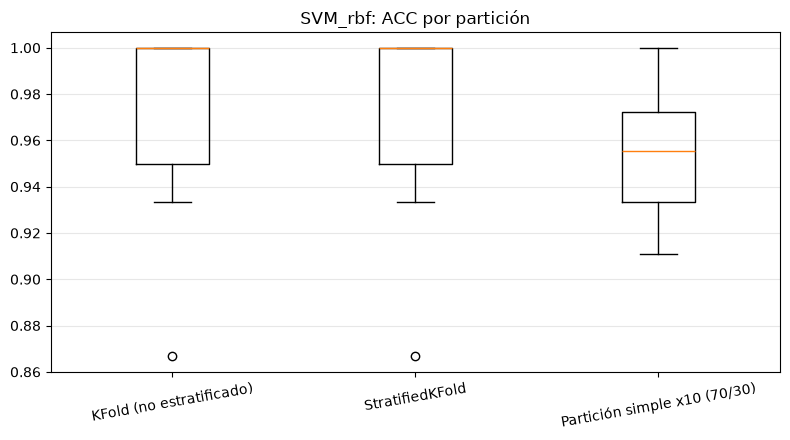

In [16]:
# mejor configuración según el 10-fold no estratificado (a igual media, menor desvío)
best = int(np.lexsort((acc_kf.std(axis=1), -acc_kf.mean(axis=1)))[0])
best_name, best_func, best_params = configs[best]
print('Mejor configuración:', best_name, best_params)

esquemas = [("KFold (no estratificado)", KFold(n_splits=NFfolds)),
            ("StratifiedKFold", StratifiedKFold(n_splits=NFfolds)),
            ("Partición simple x%d (70/30)" % NFfolds, StratifiedShuffleSplit(n_splits=NFfolds, test_size=0.3, random_state=0))]

res_val = {}
for esquema, splitter in esquemas:
    accs = []
    for train_index, test_index in splitter.split(X, Y):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = Y[train_index], Y[test_index]
        scaler = StandardScaler().fit(X_train)
        acc, _, _, _ = best_func(scaler.transform(X_train), scaler.transform(X_test), y_train, y_test, **best_params)
        accs.append(acc)
    res_val[esquema] = np.array(accs)

table = [["Esquema", "ACC Mean", "ACC STD", "ACC Var"]]
for esquema, a in res_val.items():
    table.append([esquema, '%.4f' % a.mean(), '%.4f' % a.std(), '%.5f' % a.var()])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(list(res_val.values()))
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(list(res_val), rotation=10)
ax.set_title('%s: ACC por partición' % best_name); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

* **k-fold estratificado frente a no estratificado:** Dan exactamente el mismo resultado (0.973 ± 0.044, varianza 0.00196), aunque las particiones son distintas, los folds estratificados tienen siempre 5/5/5 muestras por clase y los no estratificados llegan a 0/5/10. En ambos casos el SVM comete 4 errores, sobre los mismos puntos de la frontera *versicolor*/*virginica*. Como en k-fold cada muestra se evalúa exactamente una vez, la ACC media es $1 - \text{errores}/150$, y sólo depende de cuántos errores hay en total, no de cómo se reparten. Con clases balanceadas y un clasificador robusto, estratificar cambia poco.

* **Particionado simple repetido:** Tiene menor varianza entre particiones (0.00064 frente a 0.00196), porque cada test tiene 45 muestras en lugar de 15 y su ACC es menos ruidosa. Sin embargo, la media es más baja (0.953). Los conjuntos de test se solapan entre repeticiones y las muestras difíciles pueden aparecer varias veces, en total se cometen 21 errores en 450 evaluaciones, sobre sólo 8 muestras distintas. Además, cada modelo entrena con el 70 % de los datos en lugar del 90 %.

* De forma general, k-fold evalúa cada muestra una sola vez, por lo que su media no depende de qué muestras caen en test. El particionado simple repetido da particiones menos ruidosas, pero su media depende de qué muestras se eligen para test.

***Repetimos empleando las dos primeras componentes principales***

**Validación cruzada: particionado simple train/test**

In [17]:
# validación cruzada: partición train/test #

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=0, shuffle=True, stratify=Y)

# Estandarización de los datos
scaler = StandardScaler()
# Ajuste sobre de train
scaler.fit(X_train)
# transformación de datos train y test
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# PCA: reducción dimensional
pca = PCA(n_components=2)
# Ajuste sobre de train
pca.fit(X_train)
# transformación de datos train y test
X_train = pca.transform(X_train)
X_test = pca.transform(X_test)

vacc = []
vuar = []
vnf  = []

# llamada a cada clasificador con el fold actual
for clf in range(0,len(configs)):
    name, func, params = configs[clf]
    acc, uar, _, nf = func(X_train, X_test, y_train, y_test, **params)
    # guardo las medidas de desempeño en un vector
    vacc.append(acc)
    vuar.append(uar)
    vnf.append(nf)

# imprimo una tabla con los resultados
print(':::                  Simple CV                  :::')
table = [["Clasificador","ACC", "UAR", "# Features"]]
for clf in range(0,len(configs)):
    table.append([ configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], '%1.1f' % vnf[clf] ])
print(tabulate(table, tablefmt="fancy_grid", showindex="always",stralign="center"))

:::                  Simple CV                  :::
╒════╤══════════════╤════════╤════════╤════════════╕
│  0 │ Clasificador │  ACC   │  UAR   │ # Features │
├────┼──────────────┼────────┼────────┼────────────┤
│  1 │     NB_A     │ 0.8667 │ 0.8667 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  2 │     NB_B     │ 0.8222 │ 0.8222 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  3 │    MLP_A     │ 0.6889 │ 0.6889 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  4 │    MLP_B     │ 0.9556 │ 0.9556 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  5 │    RBF_A     │ 0.7778 │ 0.7778 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  6 │    RBF_B     │ 0.8889 │ 0.8889 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  7 │    TREE_A    │ 0.9333 │ 0.9333 │    2.0     │
├────┼──────────────┼────────┼────────┼────────────┤
│  8 │    TREE_B    │ 0.8444 │ 0.8444 │    2.0 

**K-Fold Cross Validation**

In [18]:
## K-Folds Cross Validation ##

NFfolds = 5   # >=2
Macc = [[] for i in range(len(configs))]
Muar = [[] for i in range(len(configs))]
Mnf  = [[] for i in range(len(configs))]

kf = KFold(n_splits=NFfolds)                            # non Stratified KFold
# kf = StratifiedKFold(n_splits=NFfolds)                # Stratified KFold

for train_index, test_index in kf.split(X):

    # asigno datos y etiquetas segun los índices del fold
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = Y[train_index], Y[test_index]

    # Estandarización de los datos (sobre cada fold)
    scaler = StandardScaler()
    # Ajuste sobre de train
    scaler.fit(X_train)
    # transformación de datos train y test
    X_train = scaler.transform(X_train)
    X_test = scaler.transform(X_test)

    # PCA: reducción dimensional
    pca = PCA(n_components=2)
    # Ajuste sobre de train
    pca.fit(X_train)
    # transformación de datos train y test
    X_PC_train = pca.transform(X_train)
    X_PC_test = pca.transform(X_test)

    # llamada a cada clasificador con el fold actual
    for clf in range(0,len(configs)):
        name, func, params = configs[clf]
        acc, uar, _, nf = func(X_PC_train, X_PC_test, y_train, y_test, **params)
        # guardo las medidas de desempeño en un vector
        Macc[clf].append(acc)
        Muar[clf].append(uar)
        Mnf[clf].append(nf)

# convierto a array
Macc = np.array(Macc)
Muar = np.array(Muar)
Mnf  = np.array(Mnf)
# calculo estadísticas
acc_mean = np.mean(Macc,axis=1)
uar_mean = np.mean(Muar,axis=1)
nf_mean  = np.mean(Mnf,axis=1)
acc_std = np.std(Macc,axis=1)
uar_std = np.std(Muar,axis=1)

print(':::                            k-Ffold CV                               :::')
# imprimo una tabla con los resultados
table = [["Clasificador","ACC Mean","ACC STD","UAR Mean","UAR STD", "# Features"]]
for clf in range(0,len(configs)):
    table.append([configs[clf][0], '%.4f' % acc_mean[clf], '%.4f' % acc_std[clf], '%.4f' % uar_mean[clf], '%.4f' % uar_std[clf], '%1.1f' % nf_mean[clf] ])
print(tabulate(table, tablefmt="fancy_grid", showindex="always",stralign="center"))

:::                            k-Ffold CV                               :::
╒════╤══════════════╤══════════╤═════════╤══════════╤═════════╤════════════╕
│  0 │ Clasificador │ ACC Mean │ ACC STD │ UAR Mean │ UAR STD │ # Features │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  1 │     NB_A     │  0.8933  │ 0.0389  │  0.8976  │ 0.0375  │    2.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  2 │     NB_B     │  0.8667  │ 0.0699  │  0.8771  │ 0.0582  │    2.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  3 │    MLP_A     │  0.7333  │ 0.1247  │  0.7534  │ 0.0966  │    2.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  4 │    MLP_B     │  0.8867  │ 0.0452  │  0.8995  │ 0.0271  │    2.0     │
├────┼──────────────┼──────────┼─────────┼──────────┼─────────┼────────────┤
│  5 │    RBF_A     │  0.7733  │ 0.0975  │  0.7741  │ 0.0496  │    2.0     │


#### Datos mapeados por el autocodificador y PCA

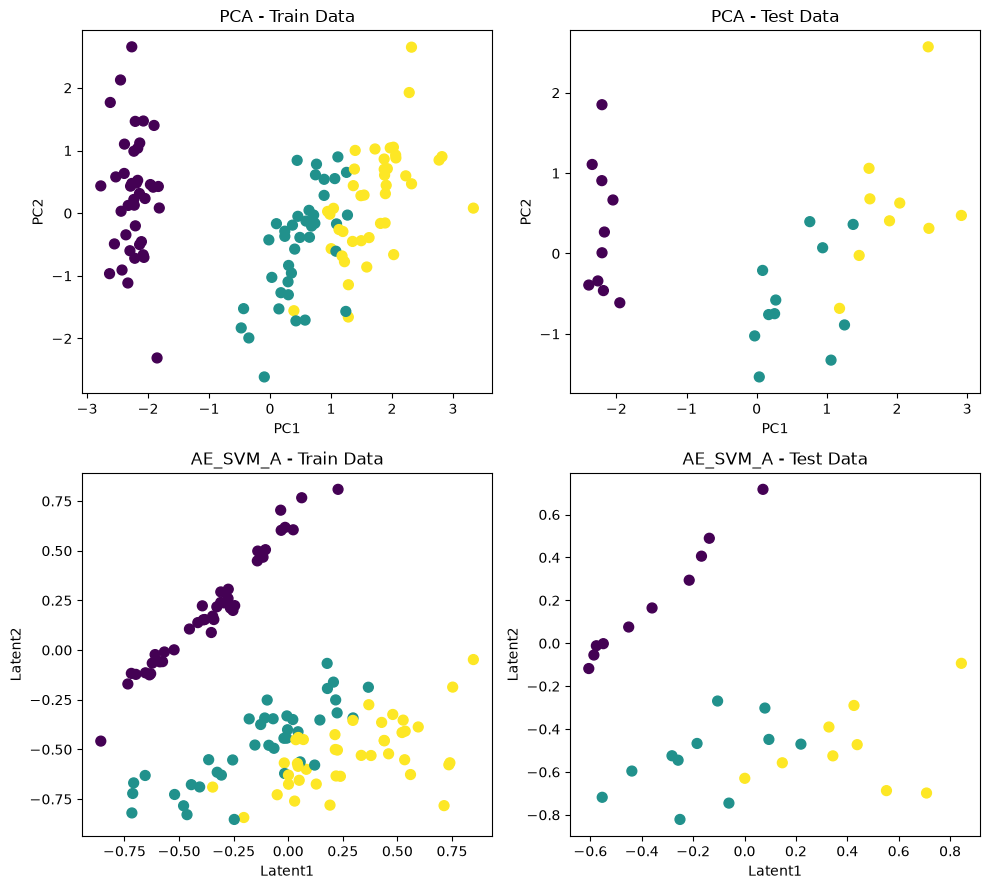

In [19]:
# Scatter plots empleando el último fold

# PCA: PC1 y PC2
fig, ([fig1, fig2], [fig3, fig4]) = plt.subplots(nrows=2, ncols=2, figsize=(10, 9))

fig1.scatter(X_PC_train[:,0], X_PC_train[:,1], s=50, c=y_train, marker="o")
fig1.set_xlabel("PC1")
fig1.set_ylabel("PC2")
fig1.set_title("PCA - Train Data")
fig2.scatter(X_PC_test[:,0],  X_PC_test[:,1],  s=50, c=y_test, marker="o")
fig2.set_xlabel("PC1")
fig2.set_ylabel("PC2")
fig2.set_title("PCA - Test Data")

# Representaciones latentes Auto-Enconder (AE_SVM_A, la configuración con mejor desempeño en el 10-fold)
ae_name, _, ae_params = [cfg for cfg in configs if cfg[0] == 'AE_SVM_A'][0]
_, _, _, _ = clf_AE_SVM(X_train, X_test, y_train, y_test, plot=True, ax1=fig3, ax2=fig4, **ae_params)
fig3.set_title(ae_name + " - Train Data")
fig4.set_title(ae_name + " - Test Data")

plt.draw()
plt.tight_layout(pad=1.08)
plt.show()

* **PCA:** Es una proyección lineal sobre las direcciones de máxima varianza. PC1 y PC2 explican el 73 % y el 23 % de la varianza (96 % en total). *Setosa* queda aislada a lo largo de PC1, y *versicolor* y *virginica* contiguas, con una zona de solapamiento.

* **Autocodificador (AE_SVM_A):** Conserva la misma estructura global sin usar las etiquetas. *Setosa* queda separada sobre una banda diagonal, y *versicolor* y *virginica* quedan contiguas, ordenadas principalmente sobre *Latent1*, con un solapamiento similar al de PCA. A diferencia de PCA, el mapeo es no lineal y está acotado a [-1, 1] por la tanh, y deforma el espacio: los puntos de *setosa* se alinean sobre una curva.

* De forma general, PCA es determinista, sus ejes están ordenados por varianza explicada y son combinaciones lineales de los atributos. Los ejes del autocodificador son arbitrarios, dependen de la inicialización y del entrenamiento. Como ninguno de los dos usa las etiquetas, ninguno garantiza maximizar la separación entre *versicolor* y *virginica*.

---

### **Ejercicio 3: dataset "Leukemia"**

In [ ]:
# Carga de datos y preprocesamiento
# Leukemia

muestras_AML = list(range(28, 39)) + [50, 51, 52, 53, 54, 57, 58, 60, 61, 62, 63, 64, 65, 66]

def cargar_leukemia(archivo):
    data = pd.read_csv(archivo)
    data = data[[col for col in data.columns if col.strip().isdigit()]]   # descarto descripción, código del gen y columnas "call"
    data.columns = [int(col) for col in data.columns]
    data = data[sorted(data.columns)]
    X = data.T.values.astype(float)
    y = np.array([1 if muestra in muestras_AML else 0 for muestra in data.columns])
    return X, y

X_train, y_train = cargar_leukemia('leukemia_train.csv')
X_test,  y_test  = cargar_leukemia('leukemia_test.csv')
print('Train: %d muestras (ALL: %d, AML: %d) | Test: %d muestras (ALL: %d, AML: %d) | Atributos: %d'
      % (len(y_train), np.sum(y_train==0), np.sum(y_train==1), len(y_test), np.sum(y_test==0), np.sum(y_test==1), X_train.shape[1]))

# Estandarización
scaler = StandardScaler()
# Ajuste sobre de train
scaler.fit(X_train)
# transformación de datos train y test
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# defino la lista de configuraciones a evaluar: (nombre, función del clasificador, parámetros)
configs = [
    ("NB",     clf_NB,     dict(priors='train')),
    ("MLP",    clf_MLP,    dict(hidden_layer_sizes=(5,3), activation='relu', learning_rate_init=0.001, max_iter=100)),
    ("RBF",    clf_RBF,    dict(n_clusters=8, sigma_scale='auto')),
    ("TREE",   clf_TREE,   dict(max_depth=2)),
    ("RF",     clf_RF,     dict(n_estimators=100)),
    ("SVM",    clf_SVM,    dict(kernel='linear', C=1.0)),
    ("kMeans", clf_kMeans, dict(n_clusters=2)),
]
# resultados de cada conjunto de características (para la comparación final)
resultados = {}

Train: 38 muestras (ALL: 27, AML: 11) | Test: 34 muestras (ALL: 20, AML: 14) | Atributos: 7129


#### Modelos

Tenemos 38 muestras de entrenamiento (27 ALL y 11 AML) y 34 de prueba (20 ALL y 14 AML), con 7129 atributos (niveles de expresión génica). Un clasificador trivial que siempre predice ALL obtiene en test ACC = 0.588 y UAR = 0.5. Igual que en los ejercicios anteriores, se estandarizan los atributos ajustando el `StandardScaler` sólo con los datos de entrenamiento. Al haber un único conjunto de prueba de 34 muestras, cada error equivale a 0.029 de ACC.

Se evalúa una configuración de cada uno de los 7 modelos. A continuación, se detallan sus características principales:

1. **Naive Bayes**: cada atributo se modela con una normal univariada por clase. Las probabilidades a priori se estiman de train ($0.71$ para ALL y $0.29$ para AML).

2. **Perceptrón multicapa**: Estructura de $d$-5-3-1, con $d$ la cantidad de atributos (ReLU, salida logística). Optimizador Adam con tasa de aprendizaje $0.001$, regularización $L_2=1e-4$, 100 épocas máximas.

3. **RBF**: Capa oculta de 8 gaussianas con centros obtenidos por *k-means* sobre train. El ancho es el desvío medio de las muestras del clúster multiplicado por $\sqrt{d}$, ya que en $d$ dimensiones la distancia típica al centro es ≈ $\sqrt{d}\,\sigma_j$ (ver Ejercicio 1). La capa de salida es un perceptrón simple.

4. **Árbol de decisión**: Criterio Gini, profundidad máxima 2.

5. **Random Forest**: 100 árboles sin límite de profundidad, *bootstrap*, $\sqrt{d}$ atributos candidatos por partición.

6. **SVM**: Kernel lineal, $C=1$. Con muchos más atributos que muestras, los datos de entrenamiento son linealmente separables y un kernel lineal es la opción habitual.

7. **K-means**: $k=2$ sobre train. Cada clúster recibe la clase mayoritaria de sus muestras de train y cada patrón de test toma la etiqueta del centroide más cercano.

#### Selección de características

* **Ranking (ANOVA F):** Se ordenan los genes según el estadístico F calculado sobre train y se toman los 20 mejores. Cada gen se evalúa por separado, sin tener en cuenta su relación con los demás.  

* **Eliminación recursiva (RFE):** Se entrena un SVM lineal con todos los genes, se elimina el de menor peso absoluto y se repite hasta quedar con 20 (`step = 1`, ≈ 7100 entrenamientos del SVM).  

* **Relief:** Para 100 muestras de train elegidas al azar, se buscan el vecino más cercano de la misma clase (*hit*) y el de la otra clase (*miss*), y se aumenta el peso de los genes que difieren más con el *miss* que con el *hit*. Se toman los 20 genes de mayor peso.  

* En los tres casos la selección se ajusta sólo con los datos de entrenamiento y se eligen 20 genes (0.3 % del total).

**Evaluación de desempeño de los clasificadores empleando las 7129 características**

In [13]:
vacc = []
vuar = []
vnf  = []
vtime = []

start_time = time.time()
# Evaluación de clasificadores con el conjunto completo de características
for clf in range(0,len(configs)):
    name, func, params = configs[clf]
    t0 = time.time()
    acc, uar, _, nf = func(X_train, X_test, y_train, y_test, **params)
    vtime.append(time.time() - t0)
    vacc.append(acc)
    vuar.append(uar)
    vnf.append(nf)
elapsed_time_2 = time.time() - start_time
resultados['Completo'] = dict(acc=vacc, uar=vuar, t_fs=0.0, t_clf=elapsed_time_2)

print(':::          Complete Feature Set             :::')
table = [["Clasificador","Accuracy","UAR", "# Features", "Tiempo [s]"]]
for clf in range(0,len(configs)):
    table.append([configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], vnf[clf], '%.3f' % vtime[clf]])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))
print("Tiempo Total Clasificadores: ", '%.4f' % elapsed_time_2)

:::          Complete Feature Set             :::
╒══════════════╤══════════╤════════╤════════════╤════════════╕
│ Clasificador │ Accuracy │  UAR   │ # Features │ Tiempo [s] │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      NB      │  0.9118  │ 0.9143 │    7129    │   0.008    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     MLP      │  0.8824  │ 0.8786 │    7129    │   0.107    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     RBF      │  0.4118  │ 0.5000 │    7129    │   0.054    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     TREE     │  0.9118  │ 0.9143 │    7129    │   0.021    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      RF      │  0.7647  │ 0.7143 │    7129    │   0.132    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     SVM      │  0.9118  │ 0.8929 │    7129    │   0.007    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│    

**Selección de características mediante método de ranking basado en ANOVA F-value**


In [14]:
# defino el método de ranking con criterio de ANOVA F (f_classif)
FS = SelectKBest(f_classif, k=20)    # definir cuántas características se desean seleccionar

start_time = time.time()
# realizo la selección en base a datos de train
FS = FS.fit(X_train, y_train)
elapsed_time = time.time() - start_time
# aplico la selección en train y test
X_train_new = FS.transform(X_train)
X_test_new  = FS.transform(X_test)

vacc = []
vuar = []
vnf  = []
vtime = []

start_time = time.time()
# Evaluación de clasificadores con las características seleccionadas
for clf in range(0,len(configs)):
    name, func, params = configs[clf]
    t0 = time.time()
    acc, uar, _, nf = func(X_train_new, X_test_new, y_train, y_test, **params)
    vtime.append(time.time() - t0)
    vacc.append(acc)
    vuar.append(uar)
    vnf.append(nf)
elapsed_time_2 = time.time() - start_time
resultados['ANOVA'] = dict(acc=vacc, uar=vuar, t_fs=elapsed_time, t_clf=elapsed_time_2)

print(':::   K-Best Ranking based on ANOVA F-value   :::')
table = [["Clasificador","Accuracy","UAR", "# Features", "Tiempo [s]"]]
for clf in range(0,len(configs)):
    table.append([configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], vnf[clf], '%.3f' % vtime[clf]])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))
print("Tiempo Selección de Características: ", '%.4f' % elapsed_time)
print("Tiempo Total Clasificadores: ", '%.4f' % elapsed_time_2)

:::   K-Best Ranking based on ANOVA F-value   :::
╒══════════════╤══════════╤════════╤════════════╤════════════╕
│ Clasificador │ Accuracy │  UAR   │ # Features │ Tiempo [s] │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      NB      │  0.9412  │ 0.9393 │     20     │   0.004    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     MLP      │  0.9412  │ 0.9286 │     20     │   0.040    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     RBF      │  0.6471  │ 0.5714 │     20     │   0.012    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     TREE     │  0.9118  │ 0.9143 │     20     │   0.004    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      RF      │  0.8824  │ 0.8571 │     20     │   0.107    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     SVM      │  0.9118  │ 0.8929 │     20     │   0.003    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│    

**Selección de características mediante el método Eliminación Recursiva (RFE) empleando SVM lineal**


In [15]:
# Defino método de evaluación
estimator = LinearSVC(random_state=0, tol=1e-5)
# Defino método de búsqueda
FS = RFE(estimator, n_features_to_select=20,       # definir cuántas características se desean seleccionar
         step=1)                                   # definir cuántas características se eliminan en cada iteración

start_time = time.time()
# Selección de características sobre datos de train
FS = FS.fit(X_train, y_train)
elapsed_time = time.time() - start_time
# Aplico selección en train y test
X_train_new = FS.transform(X_train)
X_test_new  = FS.transform(X_test)

vacc = []
vuar = []
vnf  = []
vtime = []

start_time = time.time()
# Evaluación de clasificadores con las características seleccionadas
for clf in range(0,len(configs)):
    name, func, params = configs[clf]
    t0 = time.time()
    acc, uar, _, nf = func(X_train_new, X_test_new, y_train, y_test, **params)
    vtime.append(time.time() - t0)
    vacc.append(acc)
    vuar.append(uar)
    vnf.append(nf)
elapsed_time_2 = time.time() - start_time
resultados['RFE'] = dict(acc=vacc, uar=vuar, t_fs=elapsed_time, t_clf=elapsed_time_2)

print(':::             RFE - linear SVM              :::')
table = [["Clasificador","Accuracy","UAR", "# Features", "Tiempo [s]"]]
for clf in range(0,len(configs)):
    table.append([configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], vnf[clf], '%.3f' % vtime[clf]])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))
print("Tiempo Selección de Características: ", '%.4f' % elapsed_time)
print("Tiempo Total Clasificadores: ", '%.4f' % elapsed_time_2)

:::             RFE - linear SVM              :::
╒══════════════╤══════════╤════════╤════════════╤════════════╕
│ Clasificador │ Accuracy │  UAR   │ # Features │ Tiempo [s] │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      NB      │  0.8824  │ 0.9000 │     20     │   0.003    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     MLP      │  0.9706  │ 0.9643 │     20     │   0.050    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     RBF      │  0.8529  │ 0.8643 │     20     │   0.017    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     TREE     │  0.9118  │ 0.9143 │     20     │   0.005    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      RF      │  0.8529  │ 0.8321 │     20     │   0.124    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     SVM      │  0.9706  │ 0.9643 │     20     │   0.004    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│    

**Selección de características mediante el método Relief**


In [16]:
# Selección de características mediante Relief

FS = relief.Relief(n_features=20, random_state=0) # definir cuántas características se desean seleccionar

start_time = time.time()
# Selección de características sobre datos de train
FS = FS.fit(X_train, y_train)
elapsed_time = time.time() - start_time
# Aplico selección en train y test
X_train_new = FS.transform(X_train)
X_test_new  = FS.transform(X_test)

vacc = []
vuar = []
vnf  = []
vtime = []

start_time = time.time()
# Evaluación de clasificadores con las características seleccionadas
for clf in range(0,len(configs)):
    name, func, params = configs[clf]
    t0 = time.time()
    acc, uar, _, nf = func(X_train_new, X_test_new, y_train, y_test, **params)
    vtime.append(time.time() - t0)
    vacc.append(acc)
    vuar.append(uar)
    vnf.append(nf)
elapsed_time_2 = time.time() - start_time
resultados['Relief'] = dict(acc=vacc, uar=vuar, t_fs=elapsed_time, t_clf=elapsed_time_2)

print(':::                  Relief                   :::')
table = [["Clasificador","Accuracy","UAR", "# Features", "Tiempo [s]"]]
for clf in range(0,len(configs)):
    table.append([configs[clf][0], '%.4f' % vacc[clf], '%.4f' % vuar[clf], vnf[clf], '%.3f' % vtime[clf]])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))
print("Tiempo Selección de Características: ", '%.4f' % elapsed_time)
print("Tiempo Total Clasificadores: ", '%.4f' % elapsed_time_2)

:::                  Relief                   :::
╒══════════════╤══════════╤════════╤════════════╤════════════╕
│ Clasificador │ Accuracy │  UAR   │ # Features │ Tiempo [s] │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      NB      │  0.8529  │ 0.8750 │     20     │   0.005    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     MLP      │  0.7353  │ 0.6786 │     20     │   0.042    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     RBF      │  0.9118  │ 0.9036 │     20     │   0.015    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     TREE     │  0.8235  │ 0.7857 │     20     │   0.004    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│      RF      │  0.7941  │ 0.7500 │     20     │   0.124    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│     SVM      │  0.7647  │ 0.7143 │     20     │   0.004    │
├──────────────┼──────────┼────────┼────────────┼────────────┤
│    

#### Comparación de los conjuntos de características

In [17]:
conjuntos = list(resultados)
table = [["Clasificador"] + ['%s\nACC / UAR' % s for s in conjuntos]]
for k in range(len(configs)):
    table.append([configs[k][0]] + ['%.3f / %.3f' % (resultados[s]['acc'][k], resultados[s]['uar'][k]) for s in conjuntos])
table.append(['Tiempo selección [s]'] + ['%.2f' % resultados[s]['t_fs'] for s in conjuntos])
table.append(['Tiempo clasificadores [s]'] + ['%.2f' % resultados[s]['t_clf'] for s in conjuntos])
print(tabulate(table, tablefmt="fancy_grid", stralign="center"))

╒═══════════════════════════╤═══════════════╤═══════════════╤═══════════════╤═══════════════╕
│       Clasificador        │   Completo    │     ANOVA     │      RFE      │    Relief     │
│                           │   ACC / UAR   │   ACC / UAR   │   ACC / UAR   │   ACC / UAR   │
├───────────────────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│            NB             │ 0.912 / 0.914 │ 0.941 / 0.939 │ 0.882 / 0.900 │ 0.853 / 0.875 │
├───────────────────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│            MLP            │ 0.882 / 0.879 │ 0.941 / 0.929 │ 0.971 / 0.964 │ 0.735 / 0.679 │
├───────────────────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│            RBF            │ 0.412 / 0.500 │ 0.647 / 0.571 │ 0.853 / 0.864 │ 0.912 / 0.904 │
├───────────────────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│           TREE            │ 0.912 / 0.914 │ 0.912 / 0.914 

**Conclusiones**

Los valores corresponden a ACC / UAR sobre el conjunto de prueba.

**1. Conjunto completo:** NB, TREE y SVM obtienen 0.912 (3 errores), con UAR 0.914 (NB y TREE) y 0.893 (SVM). El MLP queda en 0.882 / 0.879 y RF en 0.765 / 0.714. RBF y k-means fallan. RBF predice todo como AML (0.412 / 0.5) y k-means predice todo como ALL (0.588 / 0.5). Con 7129 atributos y sólo 38 muestras, las distancias euclídeas quedan dominadas por miles de genes no informativos, por lo que los métodos basados en distancias no encuentran una estructura asociada a las clases. En RF, la mayoría de los $\sqrt{7129} \approx 84$ genes candidatos en cada partición son ruido.

**2. Ranking ANOVA:** Mantiene o mejora el desempeño de todos los clasificadores. NB obtiene su mejor resultado (0.941 / 0.939), y también mejoran el MLP (0.941 / 0.929), RF (0.882 / 0.857), k-means (0.853 / 0.821) y RBF (0.647 / 0.571). TREE y SVM no cambian (0.912). Al quedarse con los genes cuyas medias más difieren entre clases se elimina el ruido, y las distancias pasan a reflejar la diferencia entre ALL y AML (k-means pasa de 0.588 a 0.853).

**3. RFE:** Logra los mejores resultados apra este caso. SVM y MLP llegan a 0.971 / 0.964 (un solo error). También mejoran k-means (0.912 / 0.893) y RBF (0.853 / 0.864), mientras que TREE se mantiene en 0.912. NB baja a 0.882 / 0.900 y RF queda en 0.853 / 0.832. RFE elige los genes que son útiles en conjunto para un SVM lineal, por lo que favorece al SVM y a los modelos con fronteras similares. En cambio, no tienen por qué ser los más discriminantes de forma individual, que es lo que aprovecha NB al suponer independencia (sólo 9 de los 20 genes coinciden con los de ANOVA).

**4. Relief:** Es el peor subconjunto para casi todos los clasificadores. SVM 0.765 / 0.714, MLP 0.735 / 0.679, RF 0.794 / 0.750, TREE 0.824 / 0.786, NB 0.853 / 0.875, y k-means vuelve a predecir todo como ALL (0.588 / 0.5). Los genes elegidos no coinciden con ninguno de los de ANOVA y sólo 2 coinciden con los de RFE. Por un lado, los vecinos más cercanos se calculan con los 7129 genes y sólo 38 muestras, por lo que están dominados por el ruido. Por otro, la implementación de `sklearn-relief` toma como *hit* a la propia muestra, por lo que el término que penaliza la variabilidad dentro de la clase es siempre cero y se favorecen genes con mucha varianza, no necesariamente discriminantes. La única excepción es RBF, que obtiene su mejor resultado (0.912 / 0.904), posiblemente por azar, dada la inestabilidad del perceptrón de salida vista en los ejercicios anteriores.

**5. Tiempos:** La selección con ANOVA es prácticamente instantánea (0.007 s), Relief tarda 3.2 s y RFE 40 s, ya que entrena ≈ 7100 SVM. Con 20 genes, el tiempo total de los clasificadores baja de 0.34 s a ≈ 0.17–0.21 s. La mayor reducción es la del MLP (de 0.107 s a ≈ 0.04–0.05 s), cuya capa de entrada pasa de 7129 a 20 neuronas. RF tarda ≈ 0.11–0.13 s en todos los casos, ya que su costo depende sobre todo de la cantidad de árboles. Con tan pocas muestras, el tiempo de los clasificadores es despreciable frente al de la selección.

De forma general, con ANOVA o RFE, quedarse con 20 de los 7129 genes mantiene o mejora el desempeño de casi todos los clasificadores y reduce su tiempo de entrenamiento. ANOVA tiene la mejor relación entre costo y beneficio, ya que es instantáneo y no empeora a ningún clasificador. RFE logra los mejores resultados (0.971 con SVM y MLP), a cambio de un tiempo de selección más de mil veces mayor. Relief, con esta implementación, es el peor método. Con sólo 34 muestras de prueba, diferencias de 1 o 2 errores (0.03–0.06) no son concluyentes.